# 付録: ステージ6 で図を描いていなかった経路を足す

ステージ6 のセル6（ORA）では **KEGG の 22 経路**が有意（padj < 0.05）になったが、
セル12（経路ごとの遺伝子発現 棒グラフ）とセル13（経路ごとのゲノム位置マップ ＋ 遺伝子表）で
図にしたのは **7 経路**だけだった。この付録でさらに **6 経路**を足して 13 経路にする。

| ko | 経路名 | 日本語 |
|-|-|-|
| ko00640 | Propanoate metabolism | プロピオン酸代謝 |
| ko00480 | Glutathione metabolism | グルタチオン代謝 |
| ko00660 | C5-Branched dibasic acid metabolism | C5分岐二塩基酸代謝 |
| ko00450 | Selenocompound metabolism | セレン化合物代謝 |
| ko01051 | Biosynthesis of ansamycins | アンサマイシン生合成 |
| ko04146 | Peroxisome | ペルオキシソーム |

★ **作図の手続きはステージ6 のセル12 / セル13 と完全に同じ。**
雛形は `6_pathway.ipynb` のセル12-1 とセル13-1 をそのまま写したもので、
経路ごとに違うのは `ko` / `ko_jp` / `SCHEME` を指定する **1 行だけ**である。
出力先も同じ `pathway/genebar/` と `pathway/genomepos/` で、ファイル名の付け方も同じ
（`genebar_<ko>_<scheme>.png` / `genomepos_<ko>_<scheme>.png`）。

★ **検定は1つもやり直していない。**
ORA / GSEA の結果はステージ6 が書いた `ora_all.csv` / `gsea_all.csv` を読むだけ、
pathview の図はステージ6 セル11 が書いた PNG を読むだけである。
したがってこの付録の数字はステージ6 の数字と必ず一致する。

★ **なぜ別 notebook にしたか。**
`6_pathway.ipynb` は 99 MB（画像 227 枚）あり、セルを1本足すだけでも
その読み書きが発生する。またステージ6 の中で図を足すには `ora` を作り直す必要があり、
セル6（ORA）の再実行が要る。`ora_all.csv` を読む形にすればそれが要らない。


## セル1: ライブラリ

ステージ6 セル1 と同じ。`.libPaths` を足して ggplot2 を 3.5.2 にそろえるのが目的で、この付録では clusterProfiler / fgsea の関数は使わないが、**同じ名前空間の重なり方（masking）で雛形を動かすため**に同じものを読む。


In [1]:
# ── ライブラリ ─────────────────────────────────────────────────
# ★ ステージ6 では .libPaths を足す必要がある。
#   clusterProfiler / fgsea / enrichplot は metatx-lib-4.4 側にしか無い（CLAUDE.md §10）。
#   副作用として ggplot2 が 3.5.1 → 3.5.2 に上がる。
#   ステージ5 までの図は 3.5.1 で描いたが、このnotebook の図は 3.5.2 で描かれる。
#   （gggenomes 用の 3.5.1 固定は user lib 側なので崩れない）
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))

library(dplyr)
library(tidyverse)
suppressMessages(library(clusterProfiler))
suppressMessages(library(fgsea))

cat(sprintf("R %s / clusterProfiler %s / fgsea %s / ggplot2 %s\n",
            getRversion(), packageVersion('clusterProfiler'),
            packageVersion('fgsea'), packageVersion('ggplot2')))
cat("  ※ ggplot2 が 3.5.2 になっていることを確認（metatx-lib 側）\n")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ readr     2.1.5
✔ ggplot2   3.5.2     ✔ stringr   1.6.0
✔ lubridate 1.9.4     ✔ tibble    3.3.1
✔ purrr     1.1.0     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


R 4.4.1 / clusterProfiler 4.14.6 / fgsea 1.32.4 / ggplot2 3.5.2
  ※ ggplot2 が 3.5.2 になっていることを確認（metatx-lib 側）


## セル2: パスを置く

ステージ6 セル2 をそのまま。


In [2]:
# ── パスを置く ─────────────────────────────────────────────────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_de      = file.path(path, 'DESeq2')
path_pw      = file.path(path, 'pathway')
if (!dir.exists(path_pw)) dir.create(path_pw, recursive = TRUE)

# ステージ5 の出力
f_deA = file.path(path_de, 'A_de.csv')   # (A) 全株プール 36列
f_deB = file.path(path_de, 'B_de.csv')   # (B) 株ごと 35列

# ★ KEGG の階層ファイル（経路名とカテゴリの出どころ）
#   過去プロジェクト 230313_T19_33mix の ko00001.keg（2023-11-07 取得）をコピーして使う。
#   過去notebook は /mnt/hdd2/Genome/ の CSV を読んでいたが、
#   それは hondaserver2 のパスで本サーバには無い。
#   .keg から経路名とカテゴリを直接作る方が、依存が1つ減って確実
f_keg = file.path(path, 'ref/ko00001.keg')

for (x in c(f_deA, f_deB, f_keg))
    cat(sprintf('%-24s %s\n', basename(x), ifelse(file.exists(x), 'OK', '!! 無い')))

A_de.csv                 OK
B_de.csv                 OK
ko00001.keg              OK


## セル3: ステージ5 の結果を読む（`res` を作る）

ステージ6 セル3 をそのまま。`res` はステージ6 の中でこの1か所でしか作られておらず、以降どのセルも再代入していないことを確認済み。


In [3]:
# ── ステージ5 の結果を読む ─────────────────────────────────────
# (A) と (B) を1つの表にまとめる。ステージ6 はこの表だけで進む
deA = read.csv(f_deA, stringsAsFactors = FALSE)
deB = read.csv(f_deB, stringsAsFactors = FALSE)

# B_de.csv には既に LFC_A / padj_A / stat_A / AvsB が入っている（5_2 セル11）。
# (A) にしか無い pME008 の10遺伝子を足して、全 9,795 遺伝子の表にする
res = deA %>%
    dplyr::select(gene_id, strain, product, marker, biotype, mappability,
                  contig, strand, start, end,
                  Preferred_name, KEGG_ko, KEGG_Pathway, COG_category,
                  PFAMs, EC, CAZy, Description,
                  baseMean, LFC_A = LFC_shrunk, padj_A = padj, stat_A = stat_Wald,
                  normA_WT = norm_WT_mean, normA_KO = norm_KO_mean,
                  normA_diff = norm_diff) %>%
    left_join(deB %>% dplyr::select(gene_id, LFC_B, padj_pooled, padj_bystrain,
                                    stat_B, normB_WT = normB_WT_mean,
                                    normB_KO = normB_KO_mean, normB_diff, AvsB),
              by = 'gene_id') %>%
    mutate(sigA = !is.na(padj_A)      & padj_A      < 0.05,
           sigB = !is.na(padj_pooled) & padj_pooled < 0.05)

cat(sprintf("■ res: %d 行 × %d 列\n", nrow(res), ncol(res)))

cat("\n■ Table 1: 読み込んだもの\n")
data.frame(
    item = c('(A) 全株プール', '(B) 株ごと', '統合後'),
    rows = c(nrow(deA), nrow(deB), nrow(res)),
    DEG  = c(sum(deA$padj < 0.05, na.rm = TRUE),
             sum(deB$padj_pooled < 0.05, na.rm = TRUE),
             NA),
    note = c('9,795 遺伝子（pME008 を含む）',
             '9,785 遺伝子（pME008 は dispersion を推定できず除外）',
             'pME008 の (B) 側は NA になる'),
    check.names = FALSE)

cat("\n■ Table 2: (A) vs (B) の4分類（ステージ6 の2パネル図の基礎）\n")
res %>% dplyr::count(AvsB, name = 'n') %>%
    mutate(pct = round(100 * n / sum(n), 1)) %>% as.data.frame()

■ res: 9795 行 × 35 列

■ Table 1: 読み込んだもの


item,rows,DEG,note
<chr>,<int>,<int>,<chr>
(A) 全株プール,9795,3126,"9,795 遺伝子（pME008 を含む）"
(B) 株ごと,9785,2964,"9,785 遺伝子（pME008 は dispersion を推定できず除外）"
統合後,9795,NA,pME008 の (B) 側は NA になる



■ Table 2: (A) vs (B) の4分類（ステージ6 の2パネル図の基礎）


AvsB,n,pct
<chr>,<int>,<dbl>
(A) のみ有意,851,8.7
(A) 有意 / (B) 未検定,5,0.1
(B) のみ有意,687,7.0
(B) 有意 / (A) 未検定,8,0.1
どちらも有意でない,5965,60.9
両方で有意,2269,23.2
NA,10,0.1


## セル4: ORA / GSEA と正規化カウントを読み、定数を置く（準備）

ステージ6 のセル12 準備・セル13 準備を1つにまとめ、`ora` / `gsea` は再計算せず CSV から読む形にしたもの。


In [4]:
# ── セル4: ORA / GSEA と正規化カウントを読み、定数を置く（準備）──────
# ★ 作図用のライブラリはここで読む
#   ステージ6 ではセル12 準備が ggbeeswarm を、セル13 準備が ggrepel / ggpubr / png / grid を
#   読んでいた。雛形（セル12-x）は library() を自分では呼ばないので、
#   ここで読まないと geom_quasirandom が見つからずに止まる（実測）
library(ggplot2); library(ggbeeswarm); library(ggtext); library(patchwork)
library(ggrepel); library(ggpubr); library(png); library(grid)

# ★ ステージ6 の検定を1つもやり直さない
#   ora はステージ6 セル6 が作った直後に ora_all.csv へそのまま write.csv されており、
#   gsea もセル8 から gsea_all.csv へ同じく書かれている。読み直せば中身は同一なので、
#   clusterProfiler の enricher も fgsea も回さない。
#   この付録がやるのは「既にある検定結果から、まだ描いていない経路の図を描く」ことだけ
ora  = read.csv(file.path(path_pw, 'ora_all.csv'),  stringsAsFactors = FALSE)
gsea = read.csv(file.path(path_pw, 'gsea_all.csv'), stringsAsFactors = FALSE)
cat(sprintf('ora_all.csv  %5d 行 / gsea_all.csv %5d 行\n', nrow(ora), nrow(gsea)))

# ★ (A) と (B) の正規化カウントを両方読む（ステージ6 セル12 準備と同じ）
#   (A) 4株をまとめて1組の size factor  … 群集としての出力。菌量の変化を含む
#   (B) 株ごとに別々の size factor      … 株内の発現制御。菌量の変化を含まない
nc_A = read.csv(file.path(path_de, 'A_normalized_counts.csv'), row.names = 1, check.names = FALSE)
nc_B = read.csv(file.path(path_de, 'B_normalized_counts.csv'), row.names = 1, check.names = FALSE)
cat(sprintf('A_normalized_counts: %d 遺伝子 / B_normalized_counts: %d 遺伝子\n',
            nrow(nc_A), nrow(nc_B)))

# ステージ6 セル12 準備・セル13 準備と同じ定数（値も同じ）
col_cat  = c('ORA hit' = '#d95f02', 'DEG only' = '#7570b3', 'not DEG' = '#000000')
strains4 = c('Bth_VPI', 'Bth_St8', 'Bun_8492', 'Odo_St23')
NCOL     = 12    # 棒グラフで1行に並べるパネル数（セル12 準備と同じ）
MINW     = 0.6   # 副 contig の最小描画幅 Mb（セル13 準備と同じ）

dir_pv = file.path(path_pw, 'pathview')    # セル11 の出力。再掲に使うだけで作り直さない
dir_gb = file.path(path_pw, 'genebar')     # セル12 と同じ場所に足す
dir_gp = file.path(path_pw, 'genomepos')   # セル13 と同じ場所に足す
for (d in c(dir_gb, dir_gp)) if (!dir.exists(d)) dir.create(d, recursive = TRUE)

# ★ 今回足す6経路。ko_jp は cat() の文字出力にしか使わない
#   （図の中は ASCII のみ。CLAUDE.md。図のタイトルは ora の term 文字列から自動で入る）
KOS = data.frame(
    ko    = c('ko00640','ko00480','ko00660','ko00450','ko01051','ko04146'),
    ko_jp = c('プロピオン酸代謝','グルタチオン代謝','C5分岐二塩基酸代謝',
              'セレン化合物代謝','アンサマイシン生合成','ペルオキシソーム'),
    stringsAsFactors = FALSE)

cat("\n■ Table 1: 今回足す6経路が ORA / GSEA でどうだったか\n")
KOS %>%
    left_join(ora %>% filter(source == 'KEGG', padj < 0.05) %>%
                  transmute(ko = sub('_.*', '', term), scheme,
                            v = sprintf('%s %.1e', direction, padj)) %>%
                  tidyr::pivot_wider(names_from = scheme, values_from = v,
                                     names_prefix = 'ORA_', values_fn = function(x) paste(x, collapse='/')),
              by = 'ko') %>%
    left_join(gsea %>% filter(source == 'KEGG', padj < 0.05) %>%
                  transmute(ko = sub('_.*', '', term), scheme,
                            v = sprintf('NES %+.2f (%.1e)', NES, padj)) %>%
                  tidyr::pivot_wider(names_from = scheme, values_from = v,
                                     names_prefix = 'GSEA_'),
              by = 'ko') %>%
    mutate(across(starts_with(c('ORA_','GSEA_')), ~ ifelse(is.na(.x), '★ 有意でない', .x))) %>%
    as.data.frame()

cat("\n■ Table 2: セル11 が描いた pathview の PNG がそろっているか\n")
#   ★ セル13 の (1)(2) パネルはこのファイルを読むだけ。無ければそのパネルは飛ぶので、
#     先に全部あることを確かめる。0 バイトだと readPNG が止まるので大きさも見る
expand.grid(ko = KOS$ko, scheme = c('A','B'), kind = c('all','ORA'),
            stringsAsFactors = FALSE) %>%
    mutate(f  = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, scheme, kind)),
           ある = file.exists(f),
           KB  = ifelse(ある, round(file.size(f)/1024), NA)) %>%
    transmute(ko, scheme, kind, 状態 = ifelse(!ある, '!! 無い',
                                   ifelse(KB == 0, '!! 0 バイト', sprintf('OK %d KB', KB)))) %>%
    tidyr::pivot_wider(names_from = c(scheme, kind), values_from = 状態) %>%
    as.data.frame()

cat("\n■ Table 3: 経路ごと・株ごとの遺伝子数（ORA の Count ではなく、経路に属する全遺伝子）\n")
#   ★ 0 の株があっても経路は落とさない。「その株には無い」ことが結果（CLAUDE.md）。
#     ただし雛形（セル12-x）は遺伝子が 0 の株の段を描かないので、
#     その株は図に出ず、cat() の行数と下の表で「無い」ことを示す形になる
res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, strain, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway %in% KOS$ko) %>%
    dplyr::count(KEGG_Pathway, strain, name = 'n') %>%
    tidyr::pivot_wider(names_from = strain, values_from = n, values_fill = 0) %>%
    dplyr::rename(ko = KEGG_Pathway) %>%
    left_join(KOS, by = 'ko') %>%
    mutate(合計 = rowSums(across(all_of(strains4)))) %>%
    dplyr::select(ko, ko_jp, 合計, all_of(strains4)) %>%
    arrange(match(ko, KOS$ko)) %>%
    as.data.frame()


ora_all.csv   4692 行 / gsea_all.csv  5386 行
A_normalized_counts: 9795 遺伝子 / B_normalized_counts: 9785 遺伝子

■ Table 1: 今回足す6経路が ORA / GSEA でどうだったか


ko,ko_jp,ORA_A,ORA_B,GSEA_A,GSEA_B
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ko00640,プロピオン酸代謝,down 8.2e-03,down 1.1e-03,NES -1.69 (3.2e-02),NES -1.77 (1.7e-02)
ko00480,グルタチオン代謝,down 7.4e-04,down 7.5e-05,NES -2.09 (1.5e-03),NES -2.22 (1.1e-04)
ko00660,C5分岐二塩基酸代謝,down 3.6e-03,down 2.6e-03,NES -2.16 (4.1e-04),NES -2.10 (6.7e-04)
ko00450,セレン化合物代謝,down 2.4e-03,down 6.6e-03,NES -2.14 (8.8e-04),NES -2.25 (4.4e-05)
ko01051,アンサマイシン生合成,down 8.2e-03,down 6.6e-03,★ 有意でない,NES -1.68 (4.9e-02)
ko04146,ペルオキシソーム,down 3.5e-02,down 3.0e-02,NES -1.72 (3.9e-02),NES -1.68 (4.9e-02)



■ Table 2: セル11 が描いた pathview の PNG がそろっているか


ko,A_all,B_all,A_ORA,B_ORA
<chr>,<chr>,<chr>,<chr>,<chr>
ko00640,OK 105 KB,OK 105 KB,OK 105 KB,OK 105 KB
ko00480,OK 99 KB,OK 99 KB,OK 99 KB,OK 99 KB
ko00660,OK 81 KB,OK 81 KB,OK 81 KB,OK 81 KB
ko00450,OK 61 KB,OK 61 KB,OK 61 KB,OK 61 KB
ko01051,OK 69 KB,OK 69 KB,OK 69 KB,OK 69 KB
ko04146,OK 98 KB,OK 98 KB,OK 97 KB,OK 97 KB



■ Table 3: 経路ごと・株ごとの遺伝子数（ORA の Count ではなく、経路に属する全遺伝子）


ko,ko_jp,合計,Bth_VPI,Bth_St8,Bun_8492,Odo_St23
<chr>,<chr>,<dbl>,<int>,<int>,<int>,<int>
ko00640,プロピオン酸代謝,52,12,11,15,14
ko00480,グルタチオン代謝,17,4,4,5,4
ko00660,C5分岐二塩基酸代謝,15,4,3,6,2
ko00450,セレン化合物代謝,23,4,5,9,5
ko01051,アンサマイシン生合成,6,0,0,3,3
ko04146,ペルオキシソーム,24,4,4,8,8


### 考察: 6経路とも ORA は A/B 両方で有意、材料はすべてそろっていた

6経路とも ORA は scheme A・B の両方で有意（下がる側、padj 7.5e-05 〜 3.5e-02）、GSEA も
`ko01051` の scheme A（padj 0.10）を除いて有意（NES −1.68 〜 −2.25）。方向は全部「下がる」で、
ステージ6 セル6 の「下がる側は4株そろって一貫」と同じ向きである。
pathview の PNG は 6経路 × A/B × all/ORA の 24 枚すべてが OK で、セル13 と同じ3点構成が作れた。

★ `ko01051`（アンサマイシン生合成）は **Bth_VPI と Bth_St8 に遺伝子が1つも無い**
（6遺伝子のうち Bun_8492 3 / Odo_St23 3）。経路名は放線菌の二次代謝だが、
実際に当たっているのは transketolase だけで、経路名と実体がずれている（下の考察を参照）。

## セル5: 経路ごとの遺伝子発現 棒グラフ（追加6経路）

ステージ6 **セル12** と同じ図。1セル＝1図で、scheme A の6枚（図A5-1〜A5-6）、
続いて scheme B の6枚（図A5-7〜A5-12）。

★ 1セル＝1図にする理由はステージ6 セル12 準備と同じ。Jupyter は `cat()` の文字出力を
ひとまとめにしてから図を出すので、1セルで複数回すと見出しと図の対応が取れない。


ko00640_Propanoate metabolism（プロピオン酸代謝）  scheme A  全 52 遺伝子 / ORA hit 19


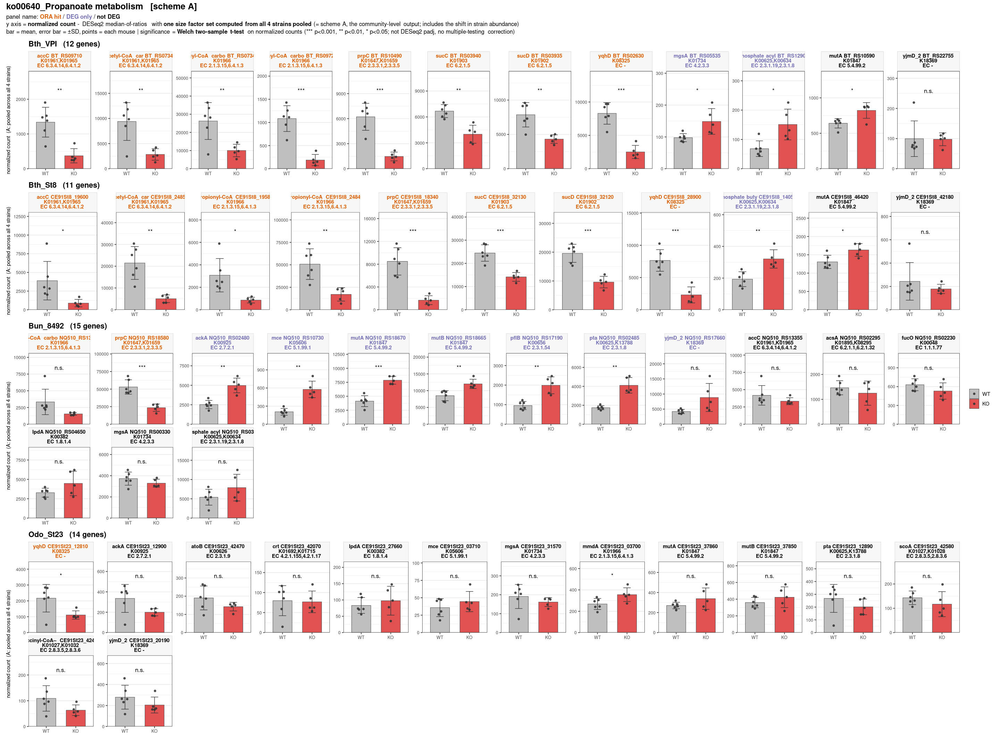

In [7]:
# ── 図A5-1: ko00640（プロピオン酸代謝）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00640'; ko_jp = 'プロピオン酸代謝'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00480_Glutathione metabolism（グルタチオン代謝）  scheme A  全 17 遺伝子 / ORA hit 11


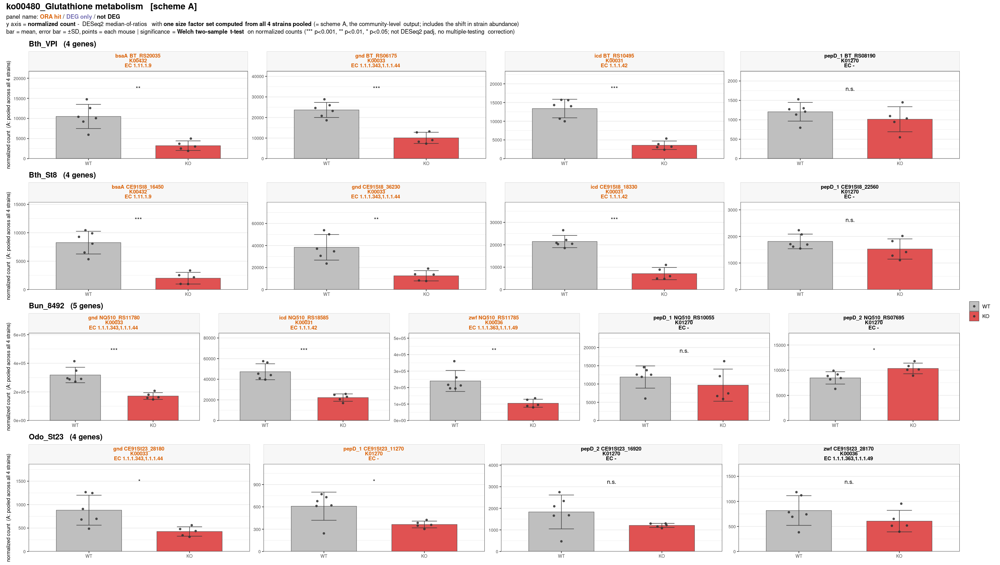

In [8]:
# ── 図A5-2: ko00480（グルタチオン代謝）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00480'; ko_jp = 'グルタチオン代謝'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00660_C5-Branched dibasic acid metabolism（C5分岐二塩基酸代謝）  scheme A  全 15 遺伝子 / ORA hit 9


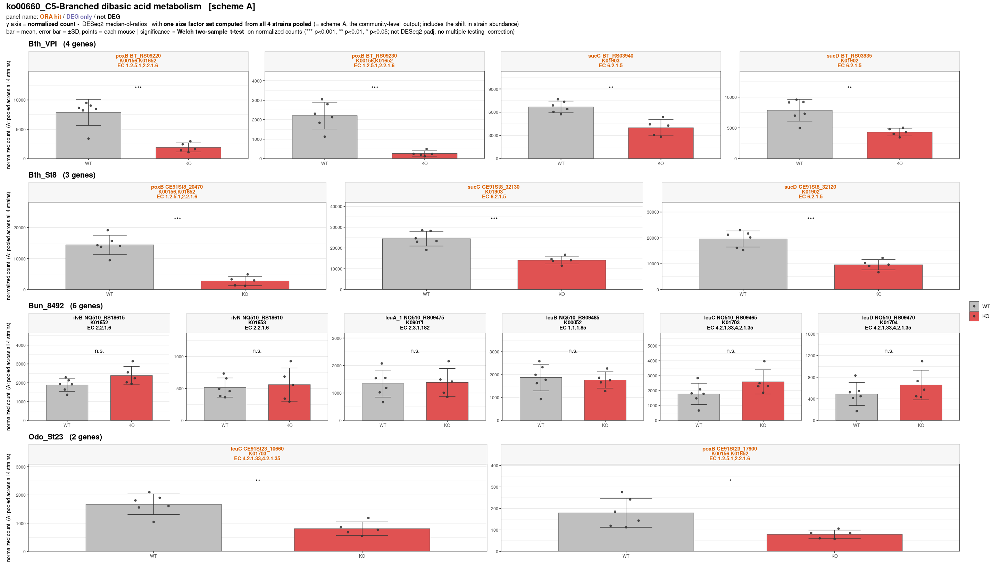

In [9]:
# ── 図A5-3: ko00660（C5分岐二塩基酸代謝）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00660'; ko_jp = 'C5分岐二塩基酸代謝'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00450_Selenocompound metabolism（セレン化合物代謝）  scheme A  全 23 遺伝子 / ORA hit 12


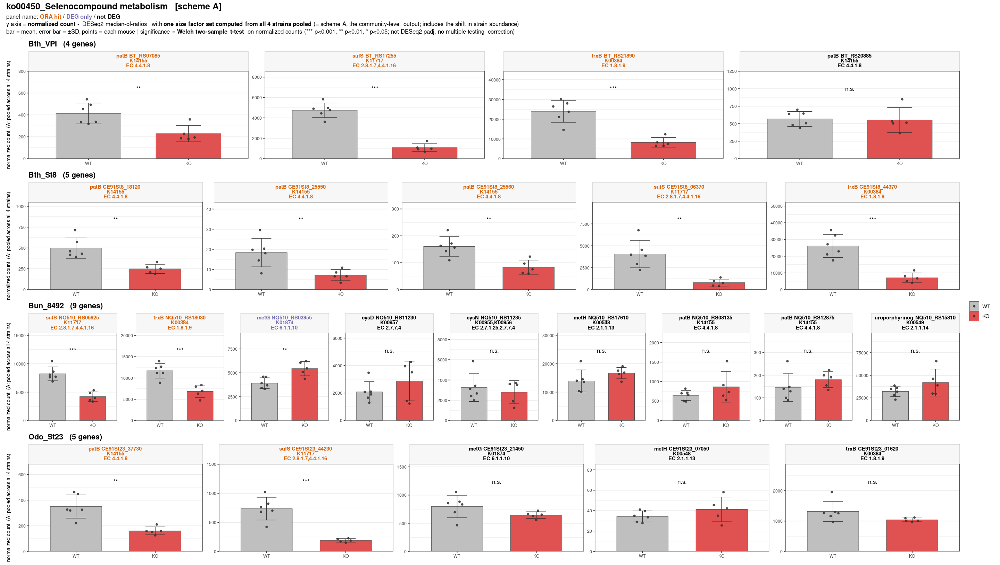

In [10]:
# ── 図A5-4: ko00450（セレン化合物代謝）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00450'; ko_jp = 'セレン化合物代謝'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko01051_Biosynthesis of ansamycins（アンサマイシン生合成）  scheme A  全 6 遺伝子 / ORA hit 5


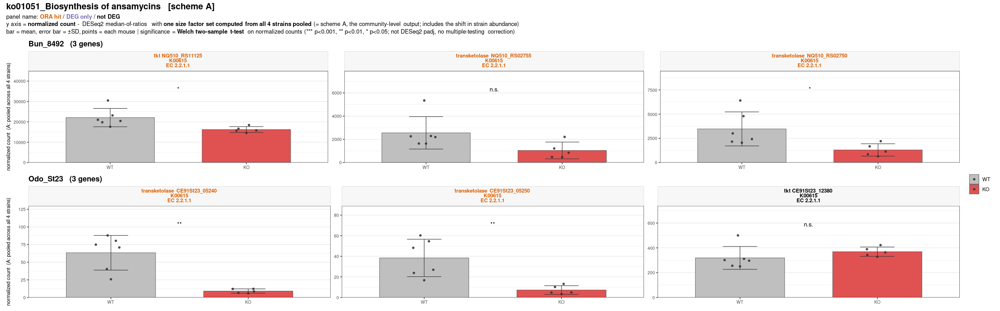

In [11]:
# ── 図A5-5: ko01051（アンサマイシン生合成）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko01051'; ko_jp = 'アンサマイシン生合成'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko04146_Peroxisome（ペルオキシソーム）  scheme A  全 24 遺伝子 / ORA hit 10


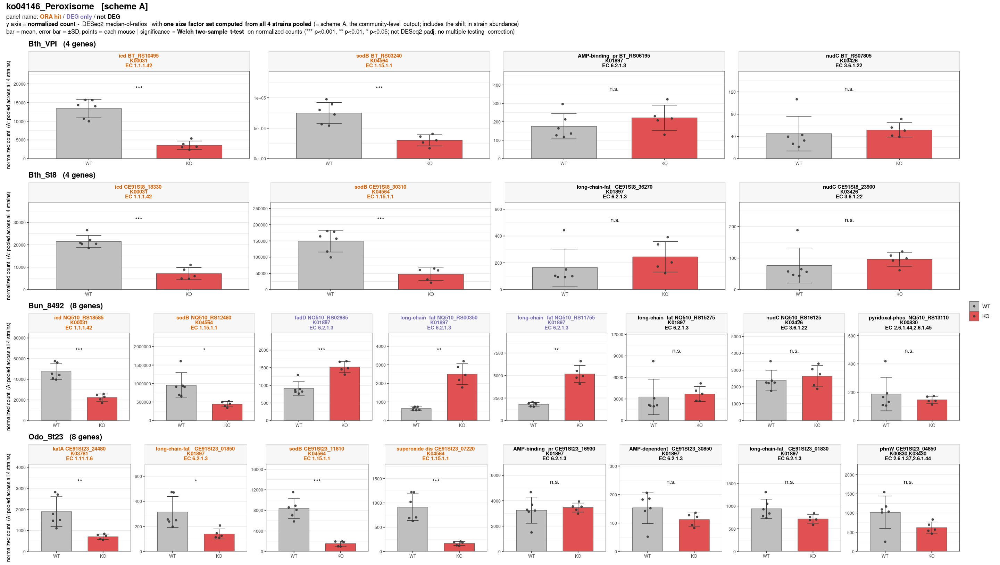

In [12]:
# ── 図A5-6: ko04146（ペルオキシソーム）  scheme A ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko04146'; ko_jp = 'ペルオキシソーム'; SCHEME = 'A'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00640_Propanoate metabolism（プロピオン酸代謝）  scheme B  全 52 遺伝子 / ORA hit 21


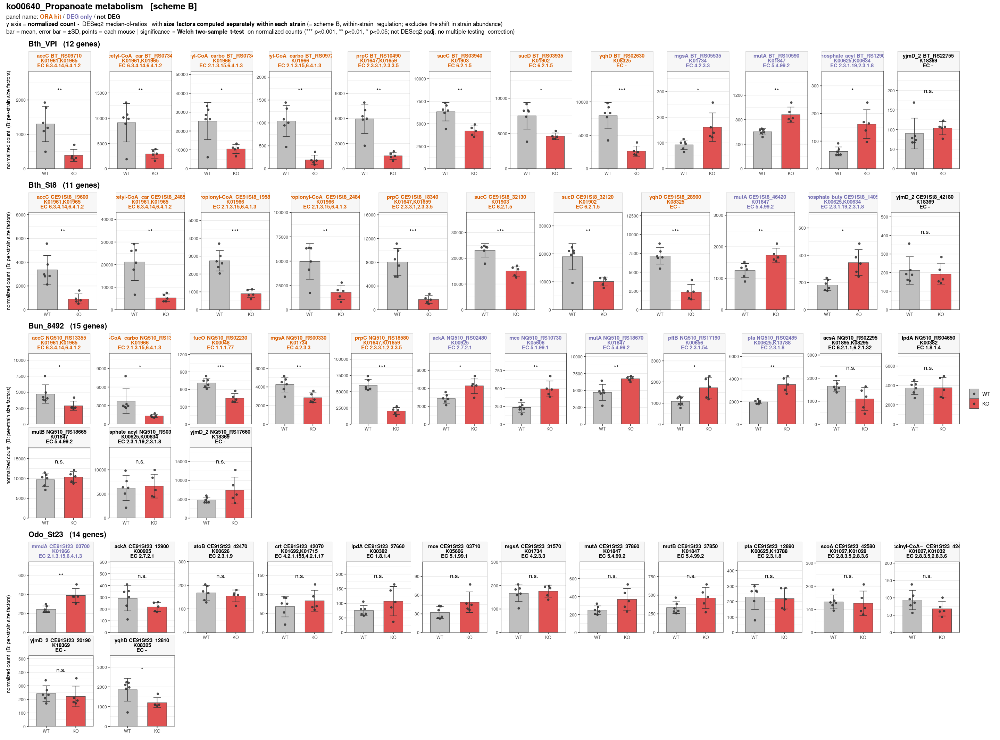

In [13]:
# ── 図A5-7: ko00640（プロピオン酸代謝）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00640'; ko_jp = 'プロピオン酸代謝'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00480_Glutathione metabolism（グルタチオン代謝）  scheme B  全 17 遺伝子 / ORA hit 12


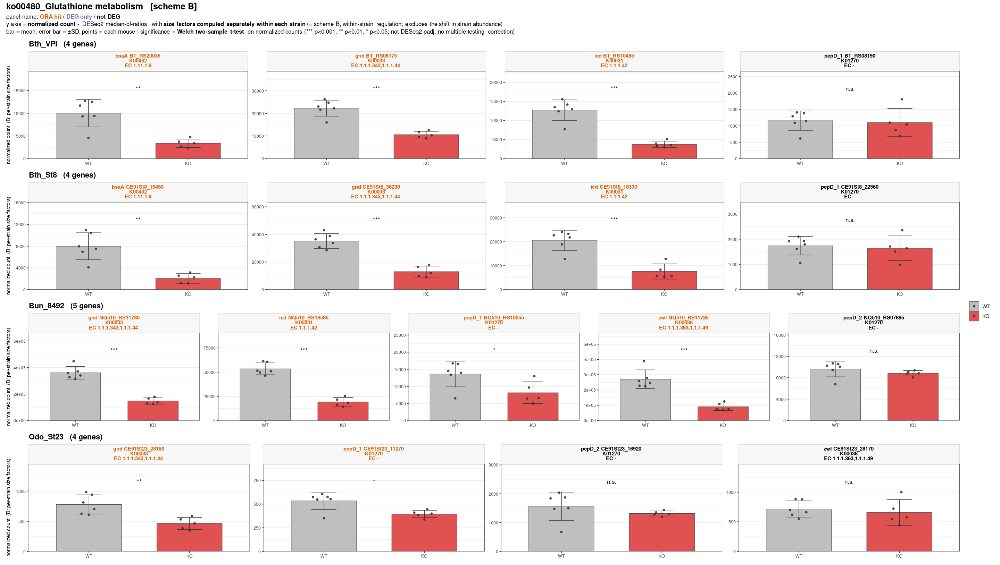

In [14]:
# ── 図A5-8: ko00480（グルタチオン代謝）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00480'; ko_jp = 'グルタチオン代謝'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00660_C5-Branched dibasic acid metabolism（C5分岐二塩基酸代謝）  scheme B  全 15 遺伝子 / ORA hit 9


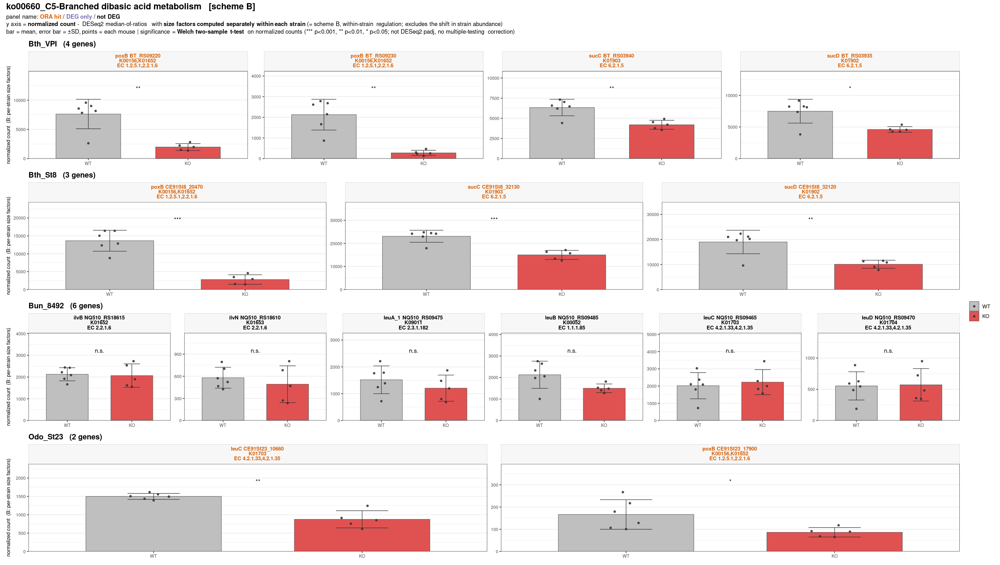

In [15]:
# ── 図A5-9: ko00660（C5分岐二塩基酸代謝）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00660'; ko_jp = 'C5分岐二塩基酸代謝'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko00450_Selenocompound metabolism（セレン化合物代謝）  scheme B  全 23 遺伝子 / ORA hit 11


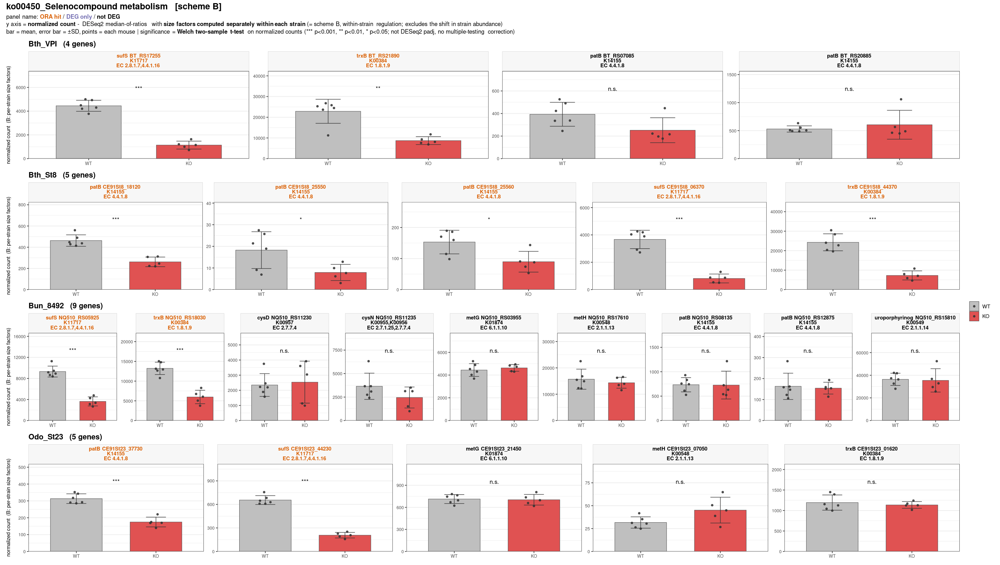

In [16]:
# ── 図A5-10: ko00450（セレン化合物代謝）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko00450'; ko_jp = 'セレン化合物代謝'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko01051_Biosynthesis of ansamycins（アンサマイシン生合成）  scheme B  全 6 遺伝子 / ORA hit 5


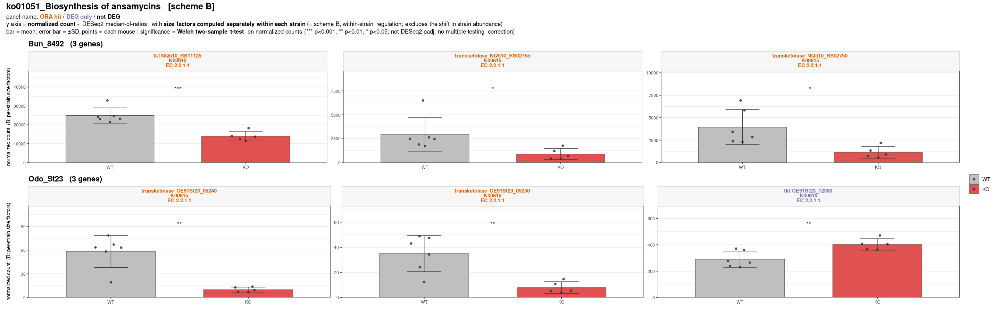

In [17]:
# ── 図A5-11: ko01051（アンサマイシン生合成）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko01051'; ko_jp = 'アンサマイシン生合成'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


ko04146_Peroxisome（ペルオキシソーム）  scheme B  全 24 遺伝子 / ORA hit 10


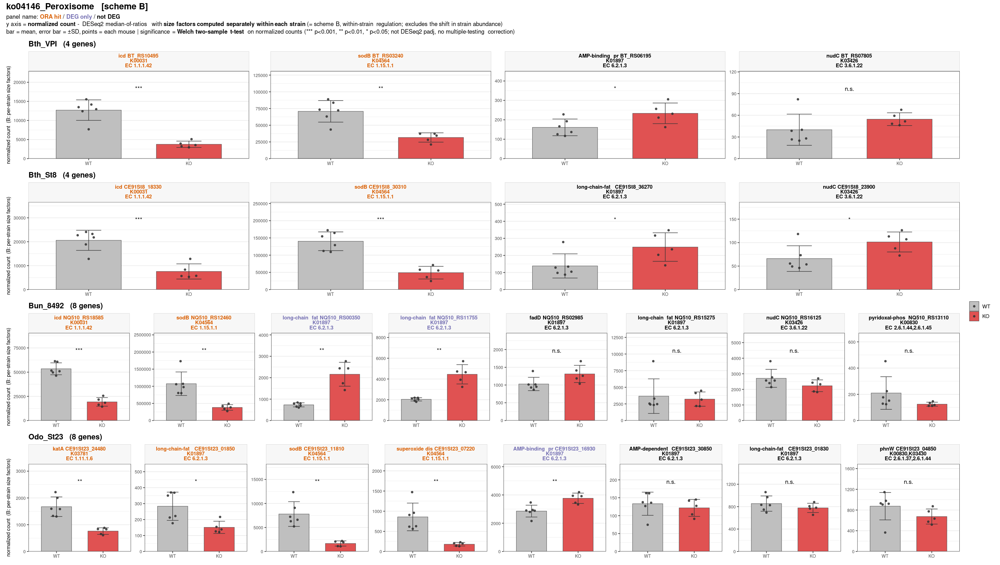

In [18]:
# ── 図A5-12: ko04146（ペルオキシソーム）  scheme B ───────────────────
# ★ ステージ6 セル12-1（図12-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと
#   （nc_A / nc_B / col_cat / strains4 / NCOL / dir_gb を使う）
ko = 'ko04146'; ko_jp = 'ペルオキシソーム'; SCHEME = 'B'

# スキームに応じて使うものを切り替える
nc       = if (SCHEME == 'A') nc_A else nc_B
y_lab = ifelse(SCHEME == 'A',
               'normalized count  (A: pooled across all 4 strains)',
               'normalized count  (B: per-strain size factors)')
sub_norm = ifelse(SCHEME == 'A',
    paste0("**one size factor set computed from all 4 strains pooled** ",
           "(= scheme A, the community-level output; includes the shift in strain abundance)"),
    paste0("**size factors computed separately within each strain** ",
           "(= scheme B, within-strain regulation; excludes the shift in strain abundance)"))

tgt = ora$term[ora$source == 'KEGG' & grepl(paste0('^', ko, '_'), ora$term)][1]

# ORA で拾われた遺伝子（down/up のどちらでも拾われていれば ORA hit）
g_ora = ora %>% filter(scheme == SCHEME, source == 'KEGG', term == tgt, padj < 0.05) %>%
    pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()

# 経路に属する全遺伝子
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
    dplyr::select(gene_id, KEGG_Pathway) %>%
    tidyr::separate_rows(KEGG_Pathway, sep = ',') %>%
    filter(KEGG_Pathway == ko) %>% pull(gene_id) %>% unique()

cat(sprintf("%s（%s）  scheme %s  全 %d 遺伝子 / ORA hit %d%s\n",
            tgt, ko_jp, SCHEME, length(g_all), length(g_ora),
            ifelse(length(g_ora) == 0, '  ★ この経路はこのスキームの ORA では有意でない', '')))

# ★ DEG の判定もスキームに合わせる（(A) は padj_A、(B) は padj_pooled）
d = nc[intersect(g_all, rownames(nc)), , drop = FALSE] %>%
    tibble::rownames_to_column('gene_id') %>%
    tidyr::pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm') %>%
    mutate(group = factor(ifelse(grepl('W', sample), 'WT', 'KO'), levels = c('WT','KO'))) %>%
    left_join(res %>% dplyr::select(gene_id, strain, Preferred_name, product,
                                    KEGG_ko, EC, padj_A, padj_pooled), by = 'gene_id') %>%
    mutate(padj_use = if (SCHEME == 'A') padj_A else padj_pooled,
           cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                           !is.na(padj_use) & padj_use < 0.05 ~ 'DEG only',
                           TRUE ~ 'not DEG'),
           cat = factor(cat, levels = names(col_cat)),
           label = ifelse(is.na(Preferred_name) | Preferred_name == '-',
                          substr(product, 1, 14), Preferred_name),
           K   = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           EC2 = sapply(strsplit(ifelse(is.na(EC), '-', EC), ','),
                        function(v) paste(head(v, 2), collapse = ',')),
           # ★ 3行にする（名前+gene_id / K番号 / EC）。
           #   1行にまとめると EC が複数ある遺伝子で左右が切れる
           panel = sprintf("<span style='color:%s'>**%s  %s<br>%s<br>EC %s**</span>",
                           col_cat[as.character(cat)], label, gene_id, K, EC2))

# ★ 検定は Welch の t 検定（R の t.test は既定が var.equal = FALSE）。
#   等分散を仮定する Student の t 検定ではない。n = 6 vs 5 で分散も揃わないため適切。
#   ★ DESeq2 の padj とは別の検定（負の二項分布 vs 正規分布）。多重比較の補正はしていない
tt = d %>% group_by(gene_id, strain, panel) %>%
    summarise(p = tryCatch(t.test(norm ~ group)$p.value, error = function(e) NA_real_),
              ymax = max(max(norm), max(tapply(norm, group, function(v) mean(v) + sd(v)))),
              .groups = 'drop') %>%
    mutate(star = cut(p, c(-Inf, .001, .01, .05, Inf), labels = c('***','**','*','n.s.')),
           star = ifelse(is.na(star), 'n.s.', as.character(star)))

# 株ごとのサブプロットを作り、patchwork で1枚にまとめる
subs = list(); hts = c()
for (s in strains4) {
    ds = d %>% filter(strain == s) %>% arrange(cat, label)
    if (nrow(ds) == 0) next
    ds$panel = factor(ds$panel, levels = unique(ds$panel))   # 分類順に並べる
    ts = tt %>% filter(strain == s) %>% mutate(panel = factor(panel, levels = levels(ds$panel)))
    n_gene = length(unique(ds$gene_id)); n_row = ceiling(n_gene / NCOL)
    subs[[s]] = ggplot(ds, aes(x = group, y = norm, fill = group)) +
        geom_bar(stat = 'summary', fun = 'mean', width = 0.65, colour = 'grey30', linewidth = 0.3) +
        # ★ SD のエラーバー（平均 ± SD の両側）。上側だけにすると errorbar が両端に
        #   キャップを描き、下のキャップが棒の上辺（＝平均）に乗って紛らわしい
        stat_summary(fun = mean,
                     fun.min = function(v) mean(v) - sd(v),
                     fun.max = function(v) mean(v) + sd(v),
                     geom = 'errorbar', width = 0.25, linewidth = 0.4, colour = 'grey20') +
        geom_quasirandom(width = 0.15, size = 1.3, alpha = 0.85, colour = 'grey20') +
        geom_text(data = ts, aes(x = 1.5, y = ymax * 1.18, label = star),
                  inherit.aes = FALSE, size = 3.6) +
        facet_wrap(~ panel, scales = 'free_y', ncol = NCOL) +
        scale_fill_manual(values = c(WT = 'grey75', KO = '#e05252'), name = NULL) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.25))) +
        labs(title = sprintf('%s   (%d genes)', s, n_gene), x = NULL, y = y_lab) +
        theme_bw() +
        # ★ strip の灰色が濃いと橙・紫の文字が沈むので、ほぼ白まで薄くする
        theme(strip.background = element_rect(fill='grey97', colour='grey75', linewidth=0.3),
              strip.text = element_markdown(size = 9),
              plot.title = element_text(size = 13, face = 'bold'),
              axis.text = element_text(size = 7.5),
              axis.title.y = element_text(size = 9),
              panel.grid.major.x = element_blank())
    hts = c(hts, n_row + 0.45)   # 株の見出し分を足す
}

P = wrap_plots(subs, ncol = 1, heights = hts) +
    plot_layout(guides = 'collect') +
    # ★ 図中に日本語を入れない（PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする）。
    #   日本語の経路名は上の cat() でテキストとして出す
    plot_annotation(title = sprintf('%s   [scheme %s]', tgt, SCHEME),
      subtitle = paste0(
        "panel name:  <span style='color:#d95f02'>**ORA hit**</span>  /  ",
        "<span style='color:#7570b3'>**DEG only**</span>  /  ",
        "<span style='color:#000000'>**not DEG**</span><br>",
        "y axis = **normalized count** - DESeq2 median-of-ratios with ", sub_norm, "<br>",
        "bar = mean, error bar = \u00b1SD, points = each mouse  |  ",
        "significance = **Welch two-sample t-test** on normalized counts ",
        "(*** p<0.001, ** p<0.01, * p<0.05; not DESeq2 padj, no multiple-testing correction)"),
      theme = theme(plot.title = element_text(size = 15, face = 'bold'),
                    plot.subtitle = element_markdown(size = 10, lineheight = 1.3)))

suppressMessages(ggsave(file.path(dir_gb, sprintf('genebar_%s_%s.png', ko, SCHEME)), P,
                        width = 24, height = 2.1 * sum(hts) + 1.4, dpi = 100, limitsize = FALSE))
options(repr.plot.width = 24, repr.plot.height = 2.1 * sum(hts) + 1.4)
P


### 考察: 5経路は既出の遺伝子の再掲、独自なのは プロピオン酸代謝 だけ

6経路とも scheme A と B でほぼ同じ絵になる（有意数の差は最大2）。
菌量の変化ではなく株内の発現制御として下がっている。

★ **下がった遺伝子の実体を見ると、5経路は既に議論した経路と遺伝子を共有している。**
KEGG が同じ遺伝子を別の経路名で再掲しているためで、経路名が増えても中身は増えていない。

- `ko00480` グルタチオン代謝 … `gnd` `zwf` `icd` ＝ ペントースリン酸経路（ko00030）と TCA（ko00020）
- `ko00660` C5分岐二塩基酸代謝 … `sucC` `sucD` `poxB` `leuC` ＝ TCA のサクシニル-CoA 合成酵素
- `ko01051` アンサマイシン生合成 … transketolase 3本のみ ＝ PPP 非酸化分枝
- `ko04146` ペルオキシソーム … `sodB` `katA` `icd` ＝ 酸化ストレス応答（ステージ7）と TCA
- `ko00450` セレン化合物代謝 … `sufS` `trxB` `patB` ＝ Fe-S クラスター組立（ステージ7 の suf 帯）とチオレドキシン

★ 独自の遺伝子を持つのは `ko00640` プロピオン酸代謝だけ（`prpC` `mutA` `mutB` `accC` `ackA` `pta`）。
ただし **株ごとに向きが逆**で、Bth_VPI は有意10のうち8が下、Bth_St8 は9のうち8が下、
Bun_8492 は逆に9のうち7が上、Odo_St23 は14遺伝子のうち有意1だけ。
ステージ6 セル12 の考察「経路が下がったの中身は株ごとにまったく違う」がそのまま当てはまる。

★ `ko00660` は **Bun_8492 だけ6遺伝子すべて有意でない**（他3株は全遺伝子が有意に低下）。

## セル6: 経路ごとのゲノム位置マップ ＋ 遺伝子表（追加6経路）

ステージ6 **セル13** と同じ図。1経路につき3つを続けて出す。

1. pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
2. pathview（ORA の geneID のみ）… ORA が拾った反応だけ
3. ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か

(1)(2) はステージ6 セル11 が描いた PNG の再掲で、6経路とも A/B の両方がそろっていることを
セル4 の Table 2 で確認している。scheme A の6枚（図A6-1〜A6-6）、続いて scheme B の6枚
（図A6-7〜A6-12）。


(1) pathview - all genes of the pathway  [ko00640.A_all.png]
(2) pathview - ORA geneID only  [ko00640.A_ORA.png]


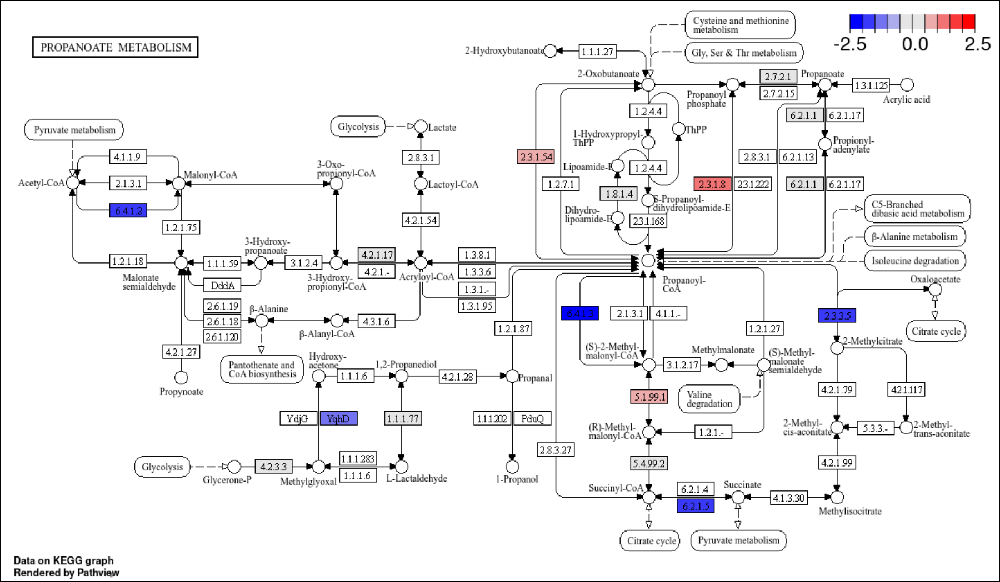

ko00640_Propanoate metabolism（プロピオン酸代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 52 / 図に出る 52（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（3 水準）

表: 52 行 → 3 ブロックに分けて横に並べる
表のフォント: 6.4 pt（最も広いブロック 7.98 inch / 1ブロックの割り当て 8.25 inch）


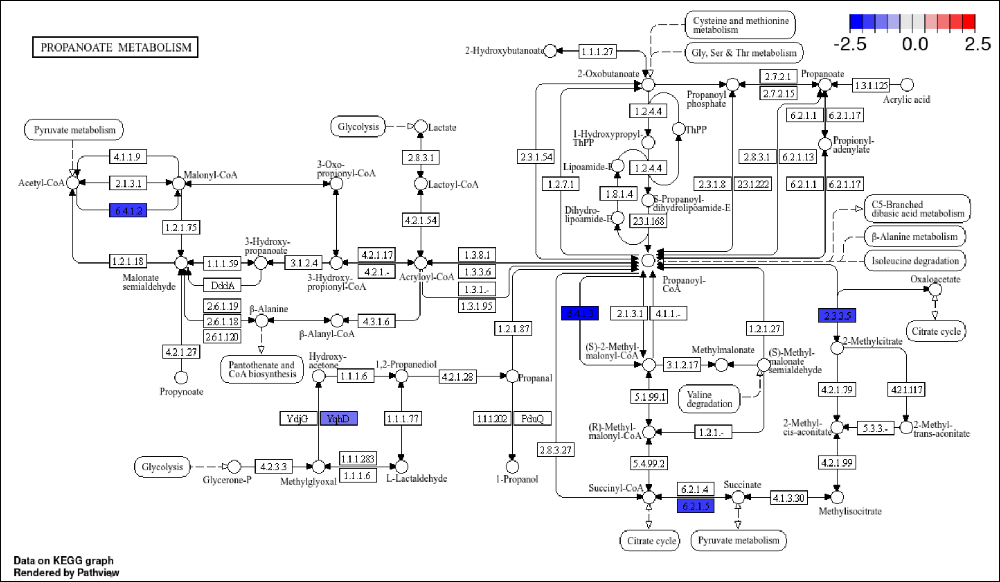

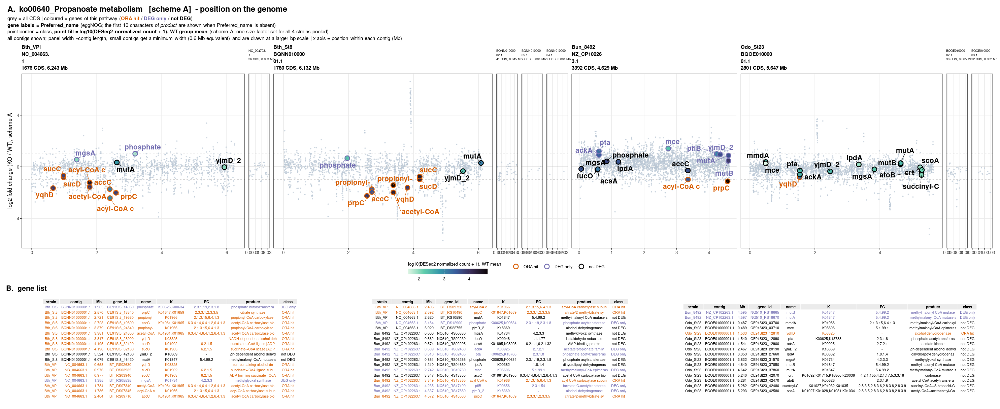

In [20]:
# ── 図A6-1: ko00640（プロピオン酸代謝）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00640'; ko_jp = 'プロピオン酸代謝'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00480.A_all.png]
(2) pathview - ORA geneID only  [ko00480.A_ORA.png]


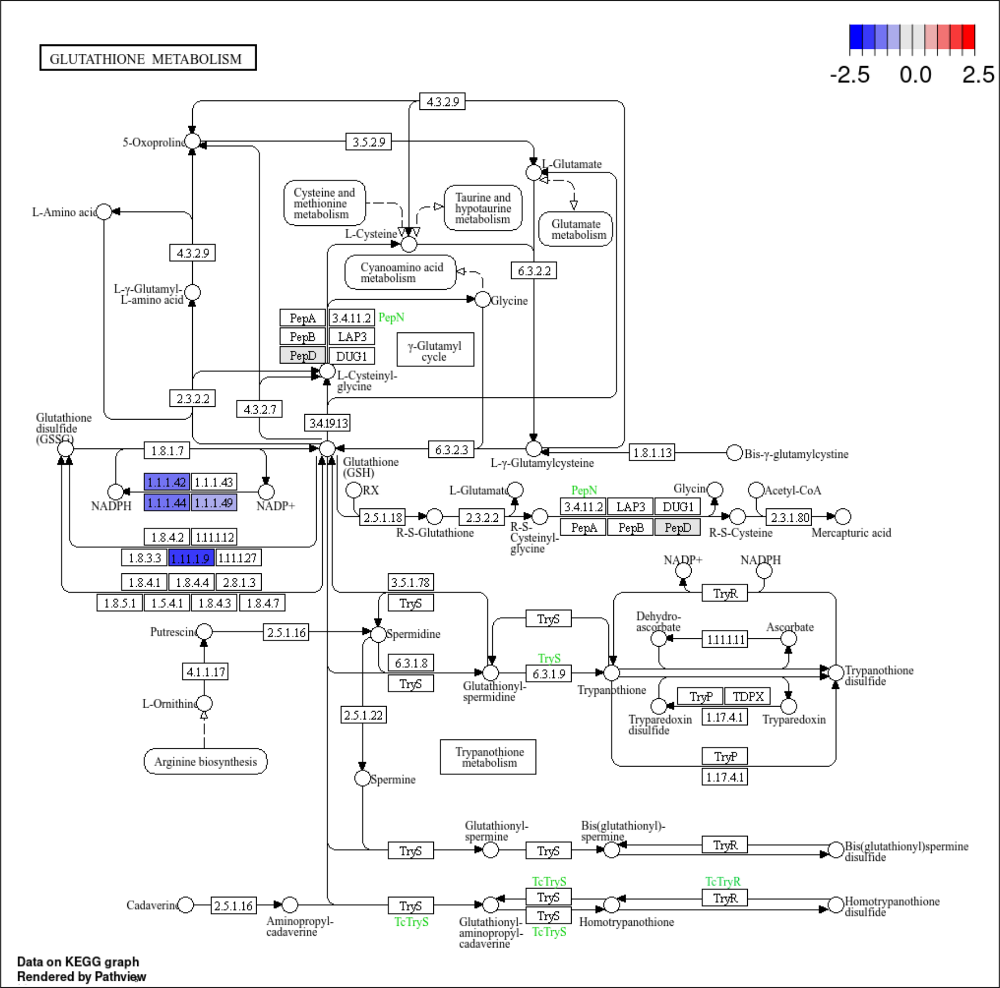

ko00480_Glutathione metabolism（グルタチオン代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 17 / 図に出る 17（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（2 水準）

表: 17 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 6.72 inch / 1ブロックの割り当て 24.75 inch）


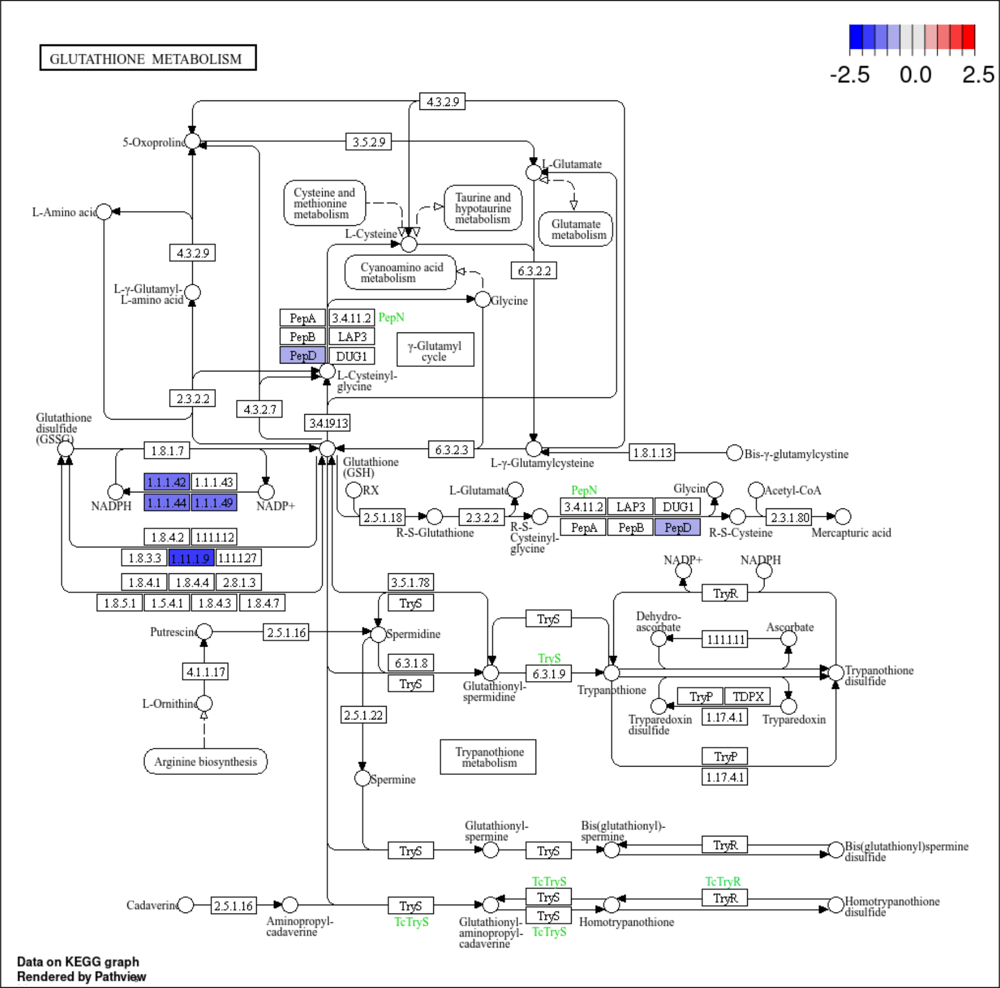

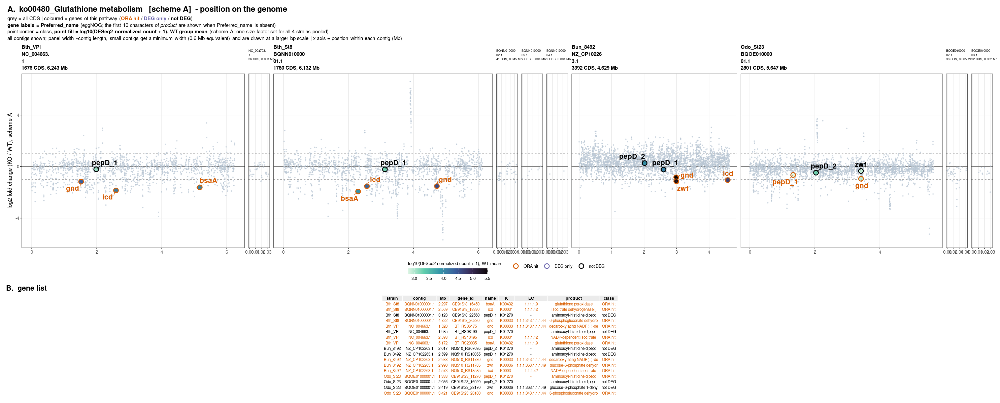

In [21]:
# ── 図A6-2: ko00480（グルタチオン代謝）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00480'; ko_jp = 'グルタチオン代謝'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00660.A_all.png]
(2) pathview - ORA geneID only  [ko00660.A_ORA.png]


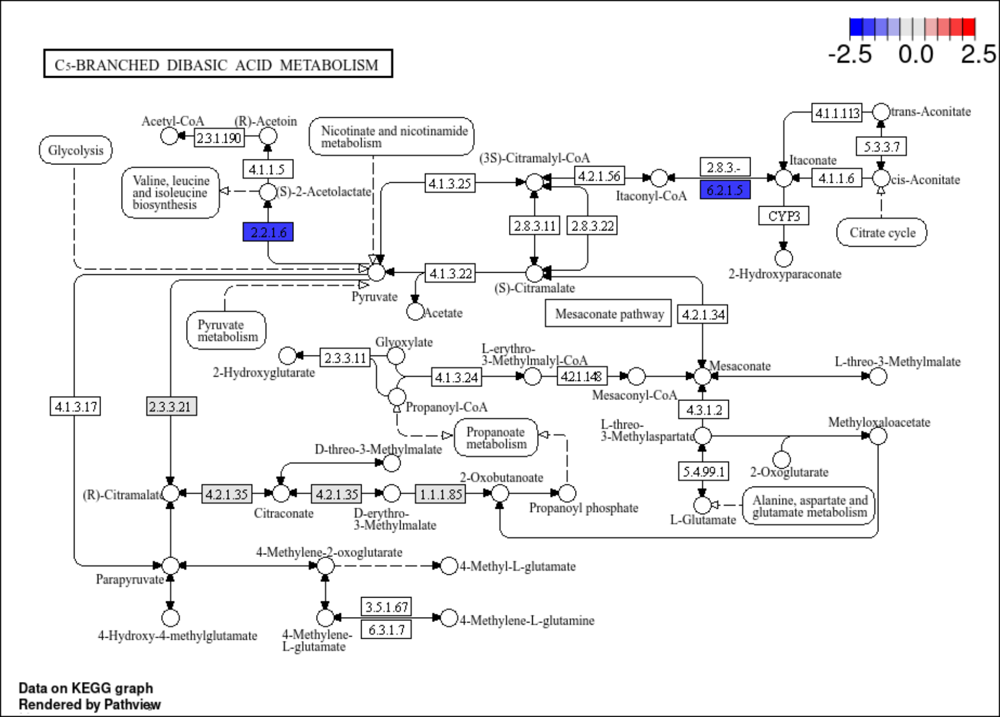

ko00660_C5-Branched dibasic acid metabolism（C5分岐二塩基酸代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 15 / 図に出る 15（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（1 水準）

表: 15 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 7.00 inch / 1ブロックの割り当て 24.75 inch）


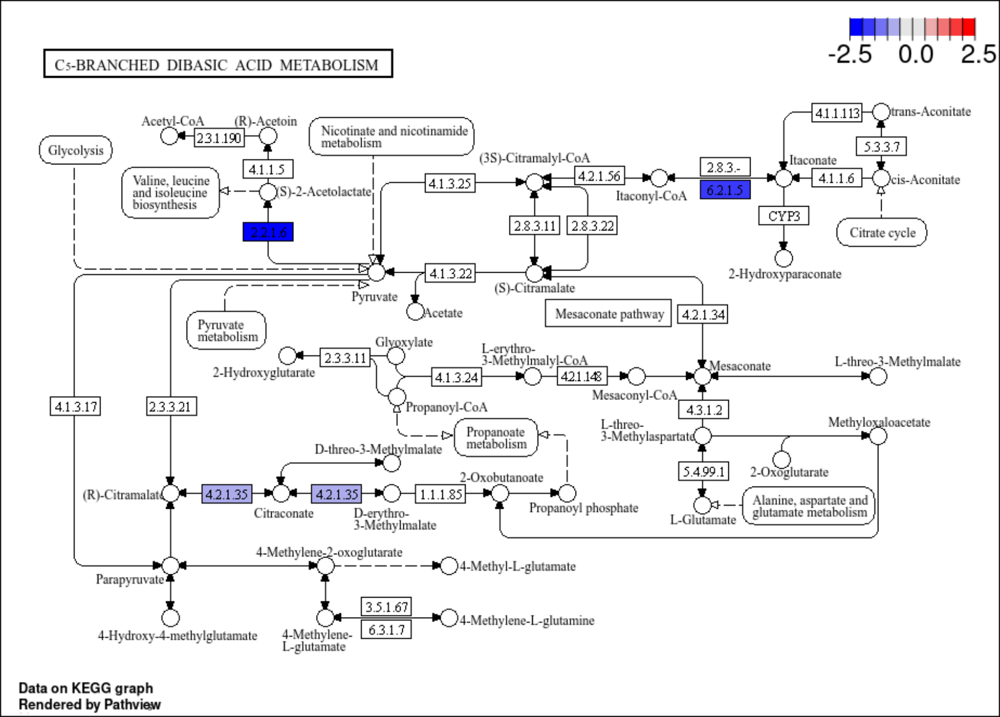

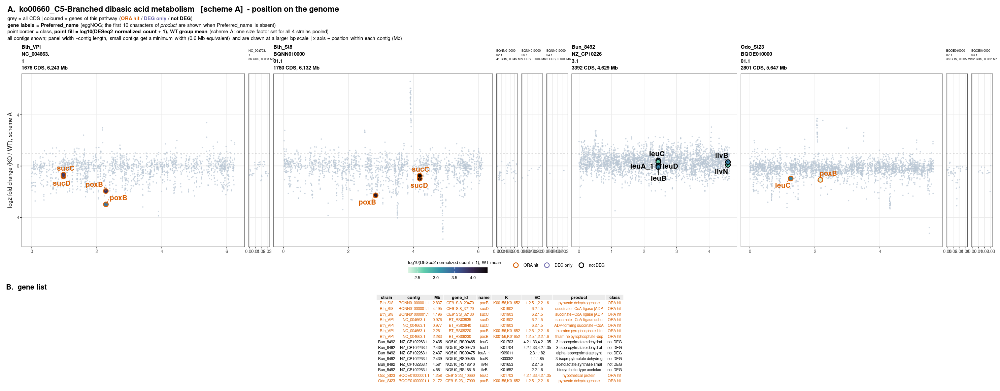

In [22]:
# ── 図A6-3: ko00660（C5分岐二塩基酸代謝）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00660'; ko_jp = 'C5分岐二塩基酸代謝'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00450.A_all.png]
(2) pathview - ORA geneID only  [ko00450.A_ORA.png]


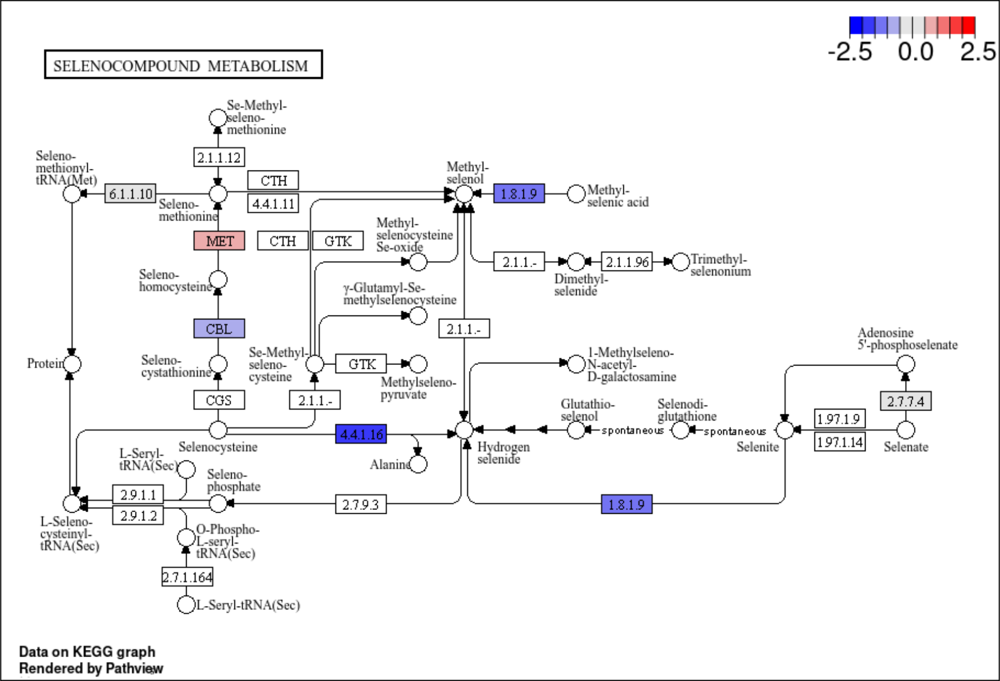

ko00450_Selenocompound metabolism（セレン化合物代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 23 / 図に出る 23（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NZ_CP102263.1（3 水準）

表: 23 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 7.21 inch / 1ブロックの割り当て 24.75 inch）


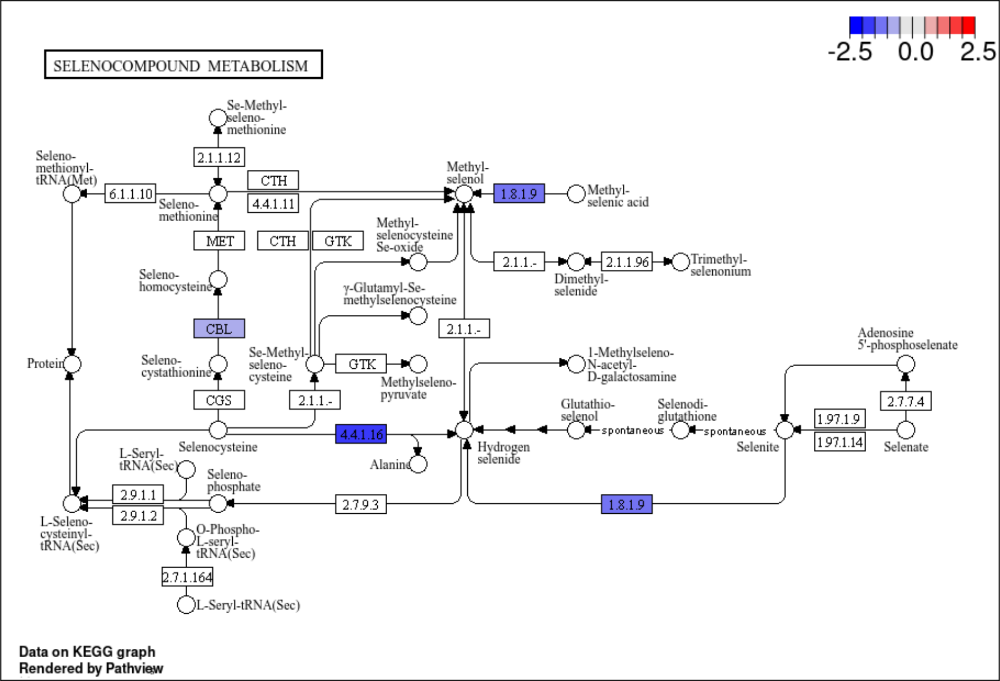

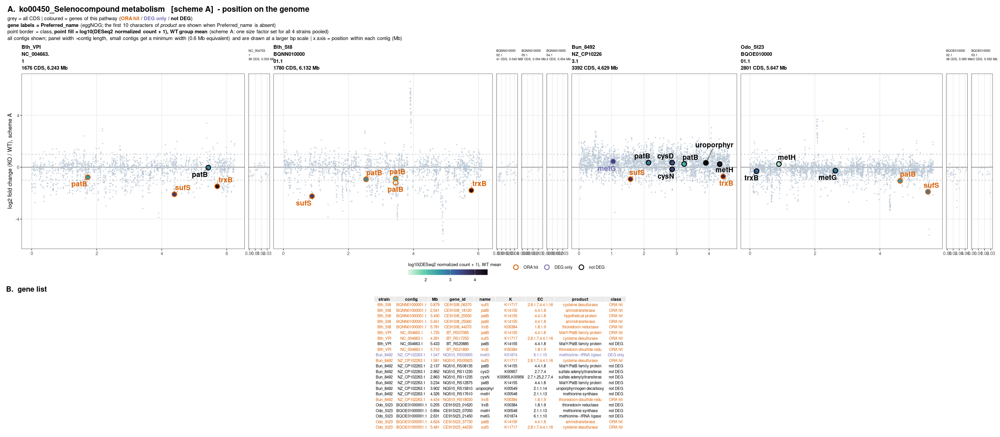

In [23]:
# ── 図A6-4: ko00450（セレン化合物代謝）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00450'; ko_jp = 'セレン化合物代謝'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko01051.A_all.png]
(2) pathview - ORA geneID only  [ko01051.A_ORA.png]


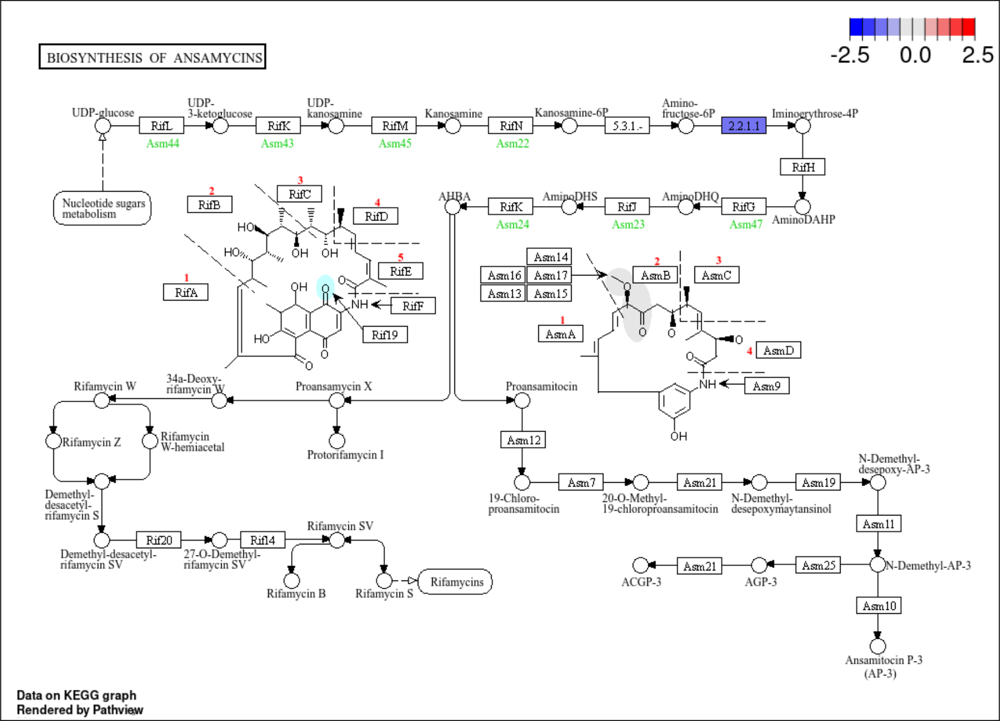

ko01051_Biosynthesis of ansamycins（アンサマイシン生合成）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 6 / 図に出る 6（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: BQOE01000001.1（2 水準）

表: 6 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 6.13 inch / 1ブロックの割り当て 24.75 inch）


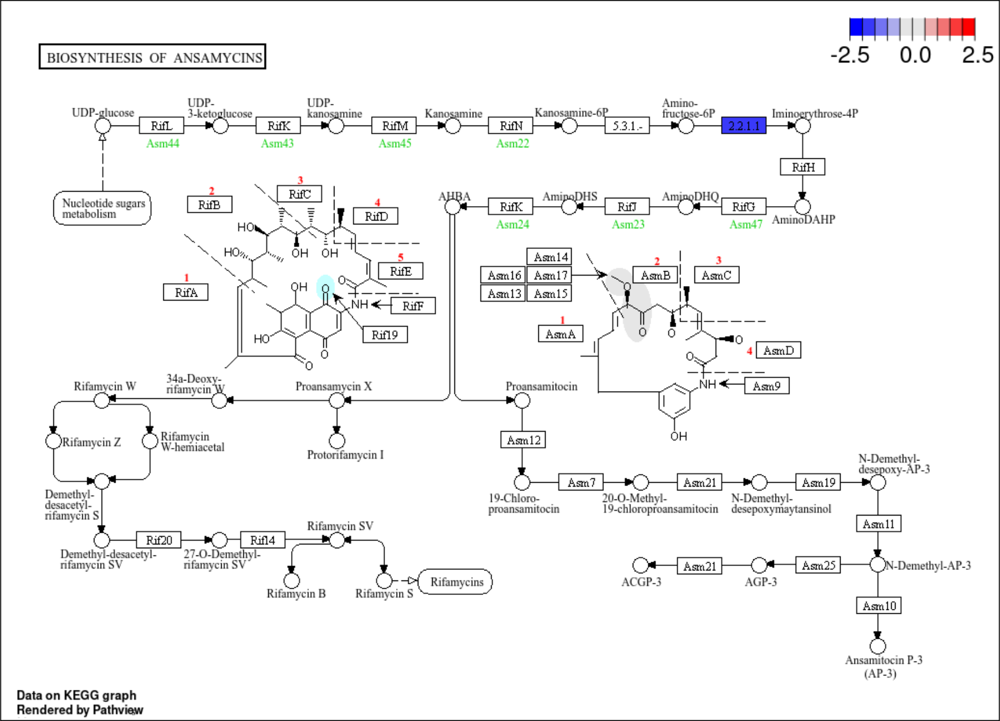

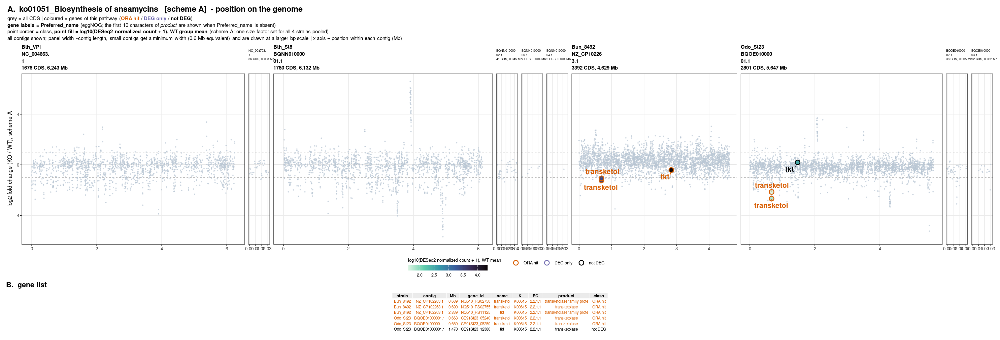

In [24]:
# ── 図A6-5: ko01051（アンサマイシン生合成）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko01051'; ko_jp = 'アンサマイシン生合成'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko04146.A_all.png]
(2) pathview - ORA geneID only  [ko04146.A_ORA.png]


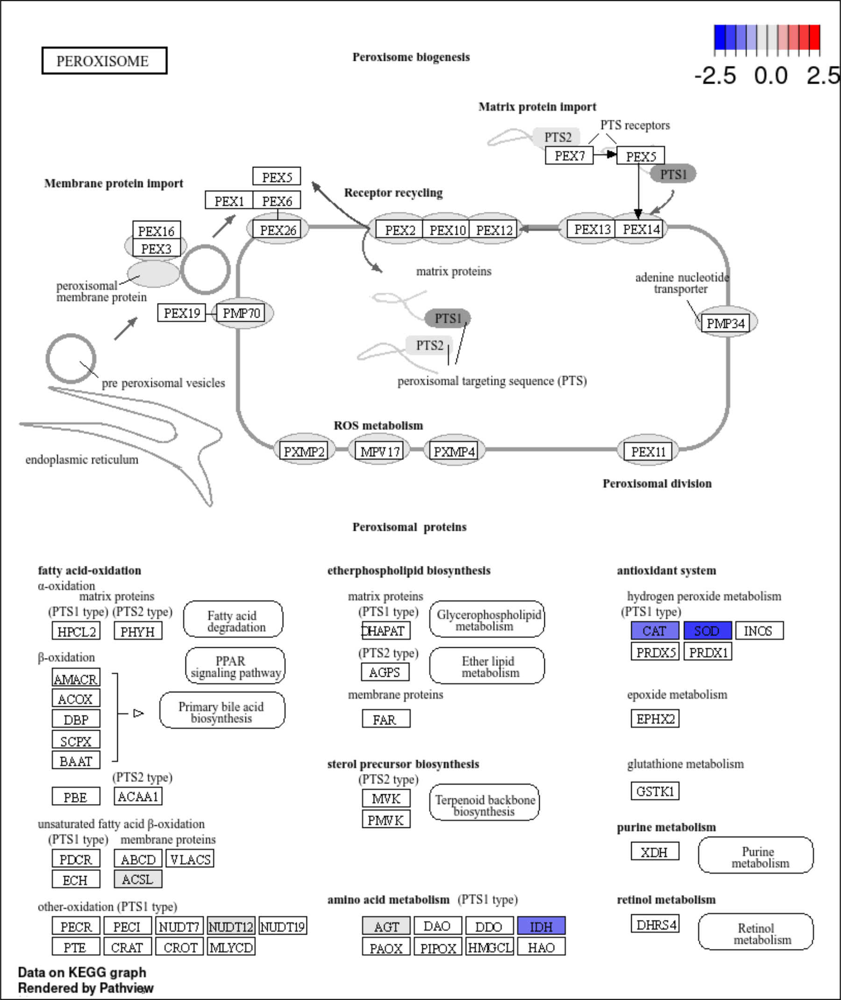

ko04146_Peroxisome（ペルオキシソーム）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 24 / 図に出る 24（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NZ_CP102263.1（3 水準）

表: 24 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 8.59 inch / 1ブロックの割り当て 24.75 inch）


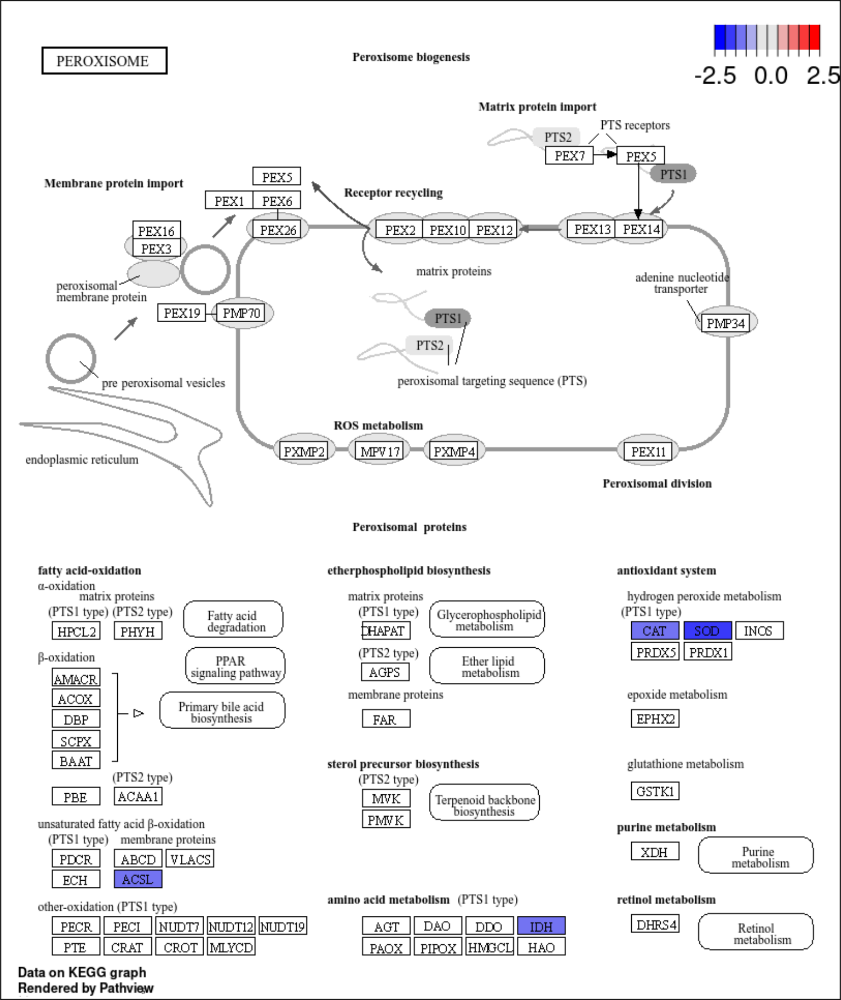

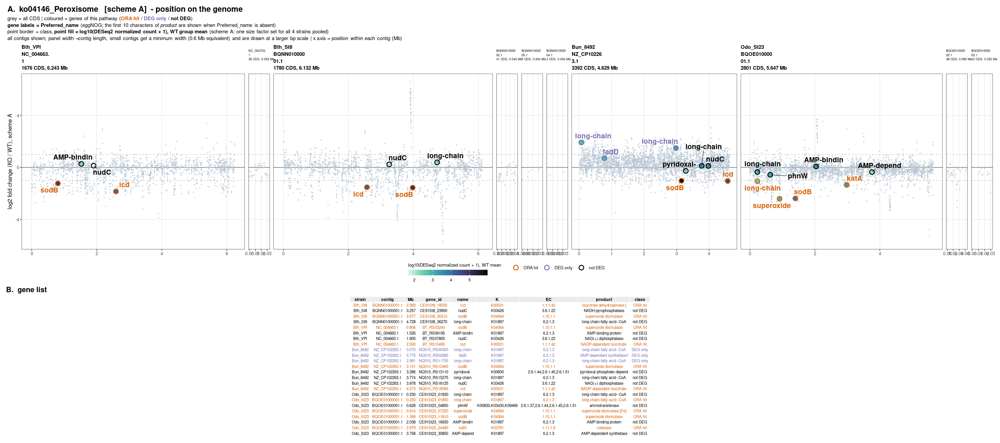

In [25]:
# ── 図A6-6: ko04146（ペルオキシソーム）  scheme A ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko04146'; ko_jp = 'ペルオキシソーム'; SCHEME = 'A'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00640.B_all.png]
(2) pathview - ORA geneID only  [ko00640.B_ORA.png]


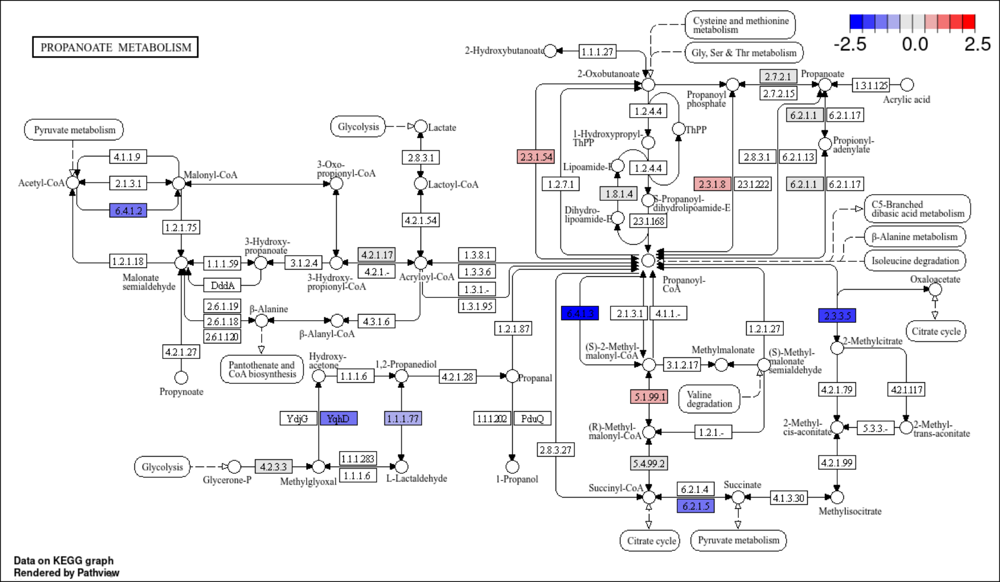

ko00640_Propanoate metabolism（プロピオン酸代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 52 / 図に出る 52（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（3 水準）

表: 52 行 → 3 ブロックに分けて横に並べる
表のフォント: 6.4 pt（最も広いブロック 7.98 inch / 1ブロックの割り当て 8.25 inch）


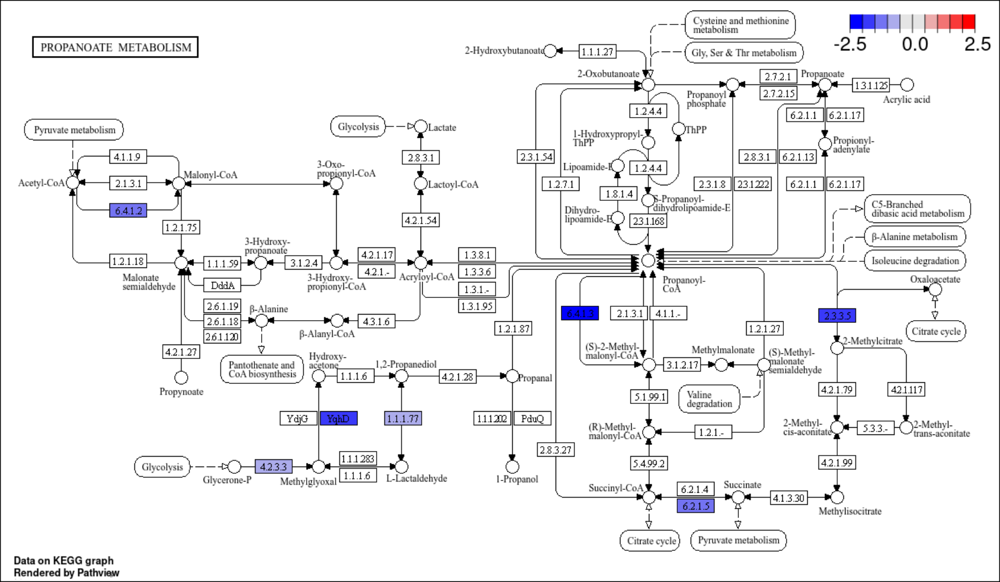

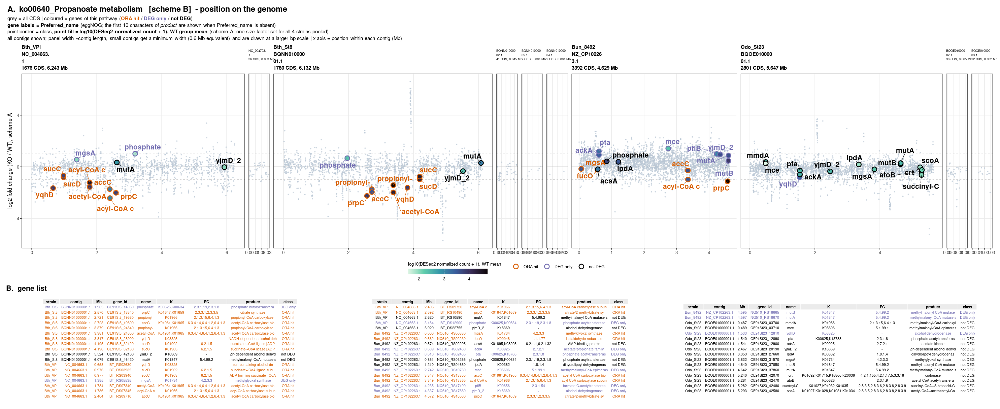

In [26]:
# ── 図A6-7: ko00640（プロピオン酸代謝）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00640'; ko_jp = 'プロピオン酸代謝'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00480.B_all.png]
(2) pathview - ORA geneID only  [ko00480.B_ORA.png]


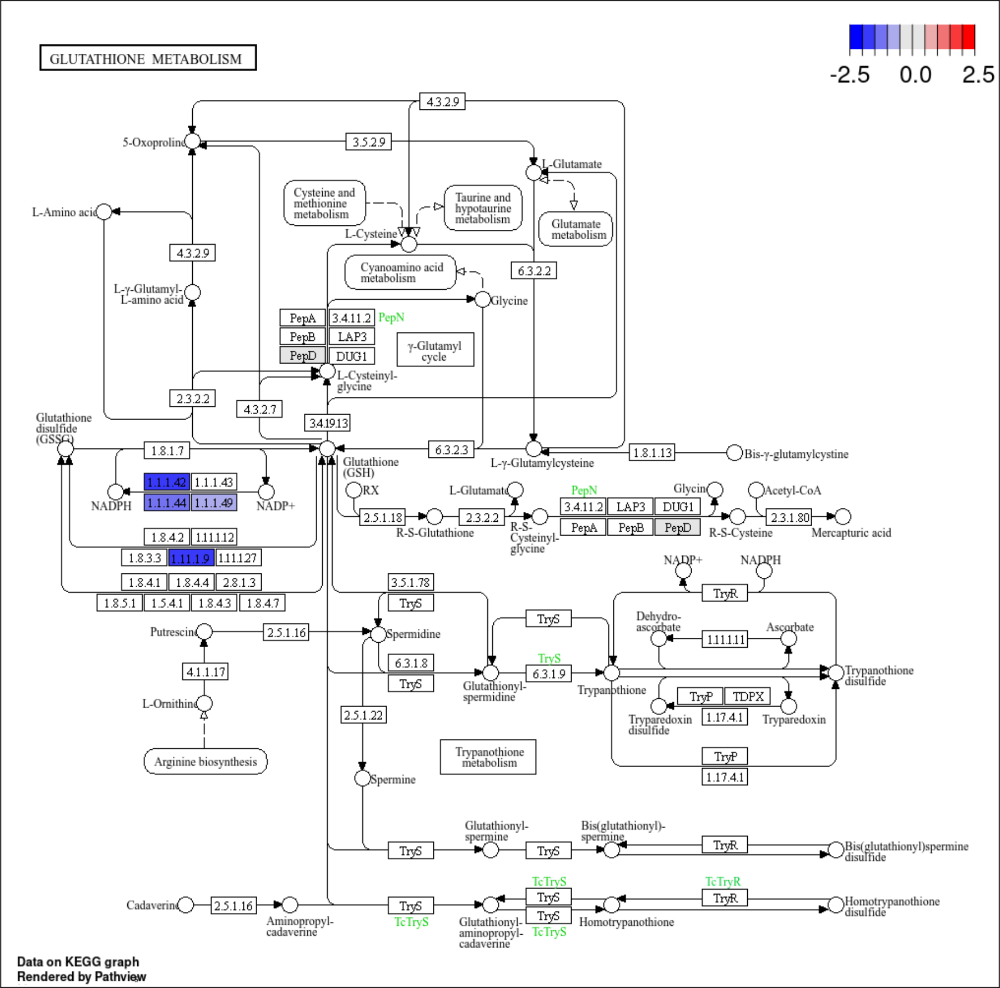

ko00480_Glutathione metabolism（グルタチオン代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 17 / 図に出る 17（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（2 水準）

表: 17 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 6.72 inch / 1ブロックの割り当て 24.75 inch）


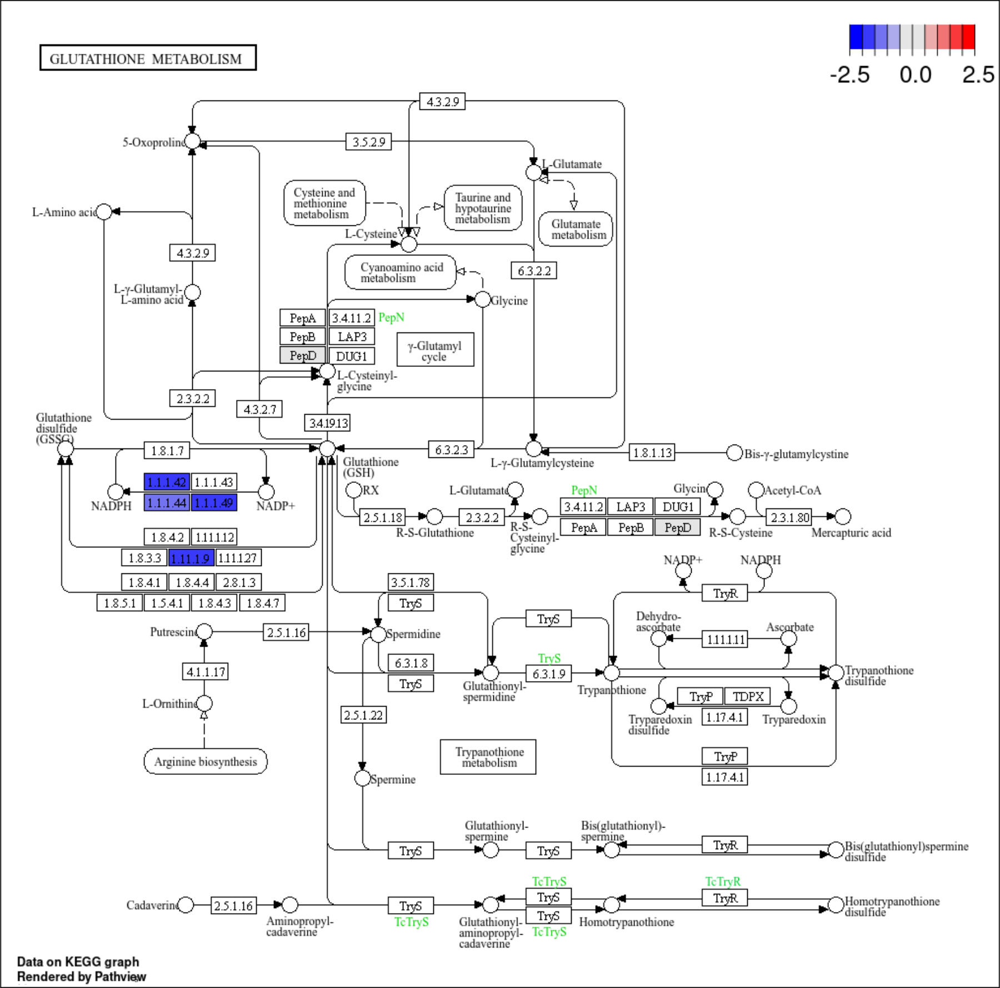

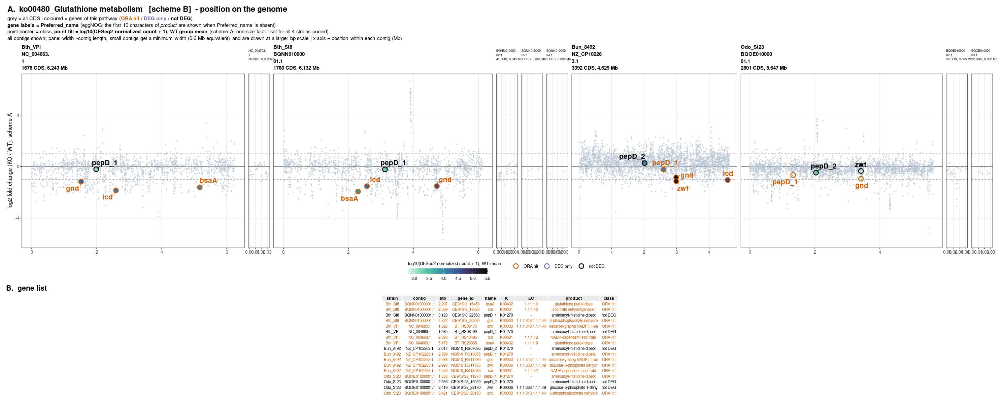

In [27]:
# ── 図A6-8: ko00480（グルタチオン代謝）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00480'; ko_jp = 'グルタチオン代謝'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00660.B_all.png]
(2) pathview - ORA geneID only  [ko00660.B_ORA.png]


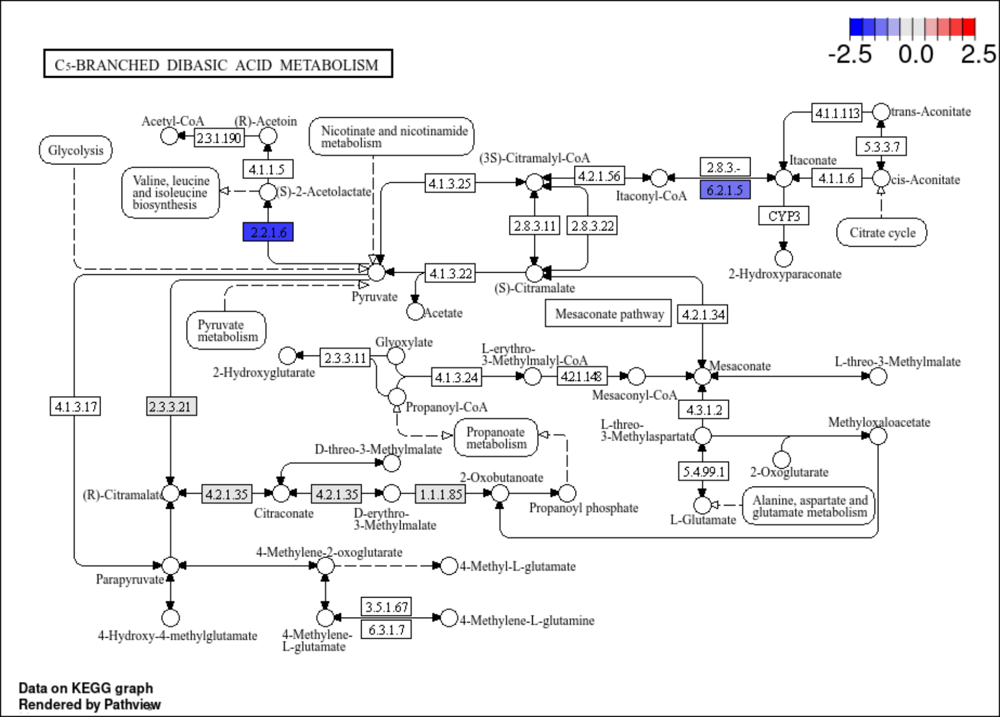

ko00660_C5-Branched dibasic acid metabolism（C5分岐二塩基酸代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 15 / 図に出る 15（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（1 水準）

表: 15 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 7.00 inch / 1ブロックの割り当て 24.75 inch）


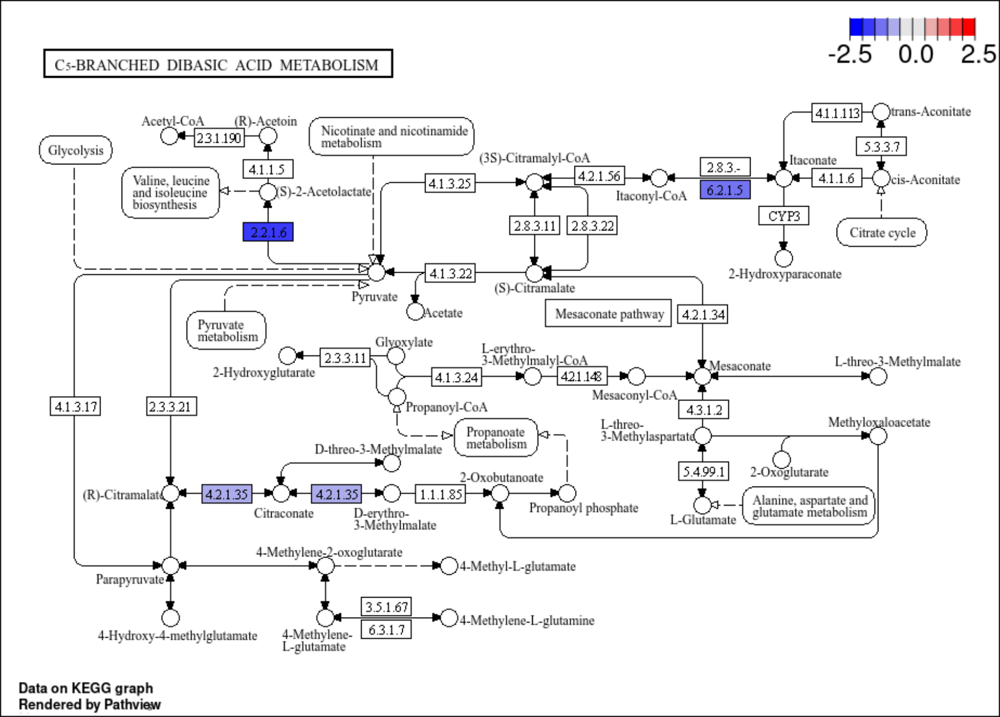

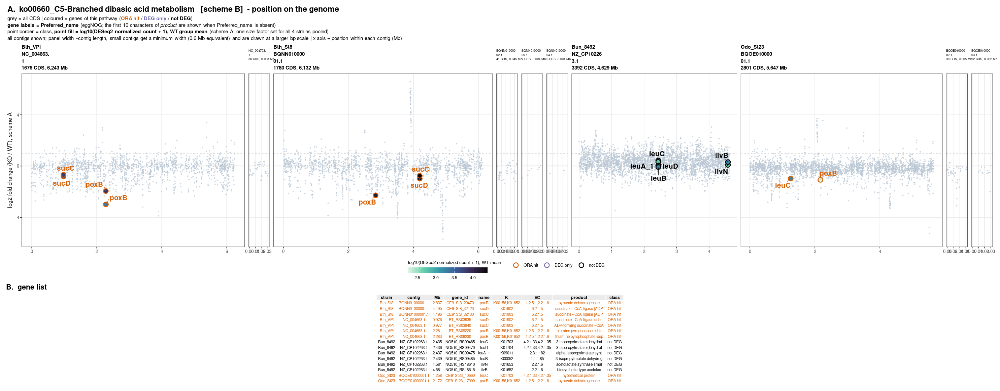

In [28]:
# ── 図A6-9: ko00660（C5分岐二塩基酸代謝）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00660'; ko_jp = 'C5分岐二塩基酸代謝'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko00450.B_all.png]
(2) pathview - ORA geneID only  [ko00450.B_ORA.png]


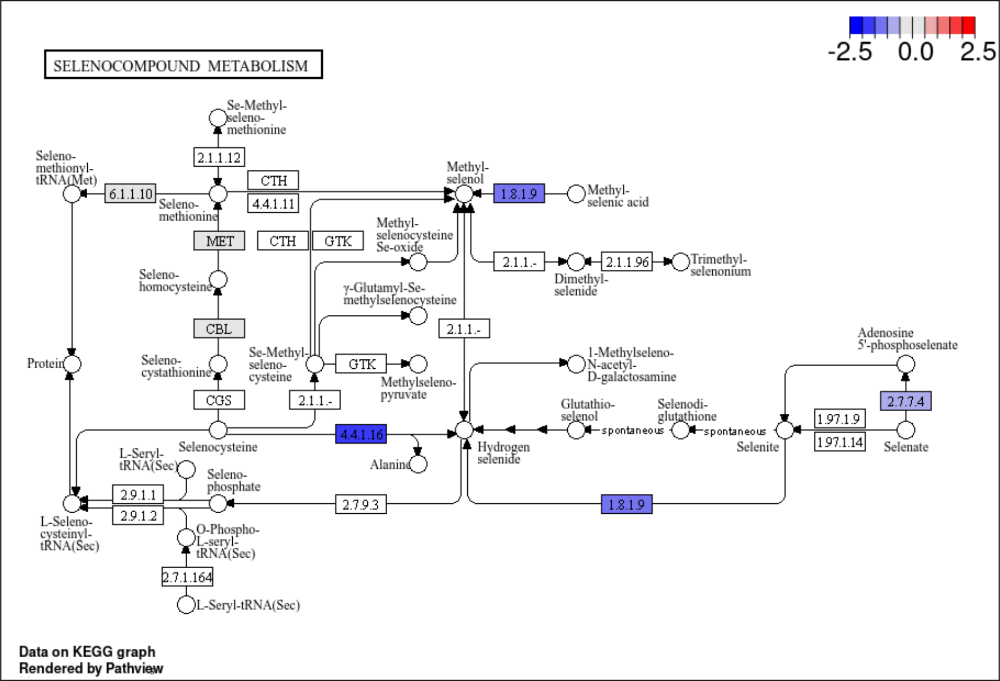

ko00450_Selenocompound metabolism（セレン化合物代謝）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 23 / 図に出る 23（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NC_004663.1（3 水準）

表: 23 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 7.21 inch / 1ブロックの割り当て 24.75 inch）


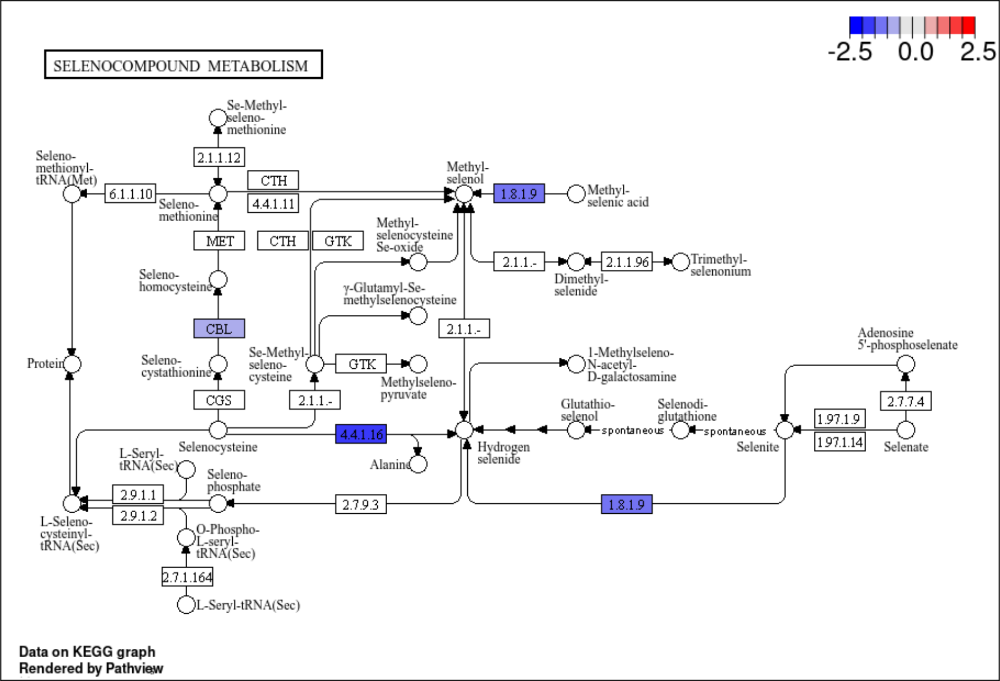

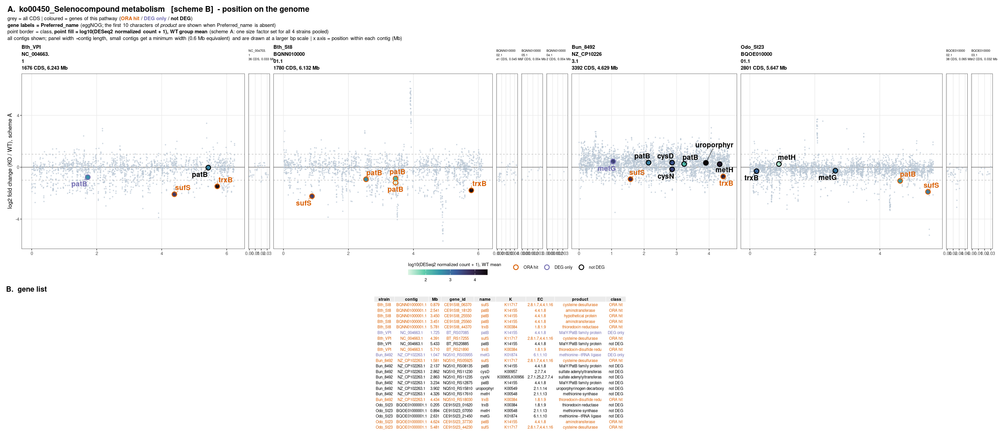

In [29]:
# ── 図A6-10: ko00450（セレン化合物代謝）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko00450'; ko_jp = 'セレン化合物代謝'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko01051.B_all.png]
(2) pathview - ORA geneID only  [ko01051.B_ORA.png]


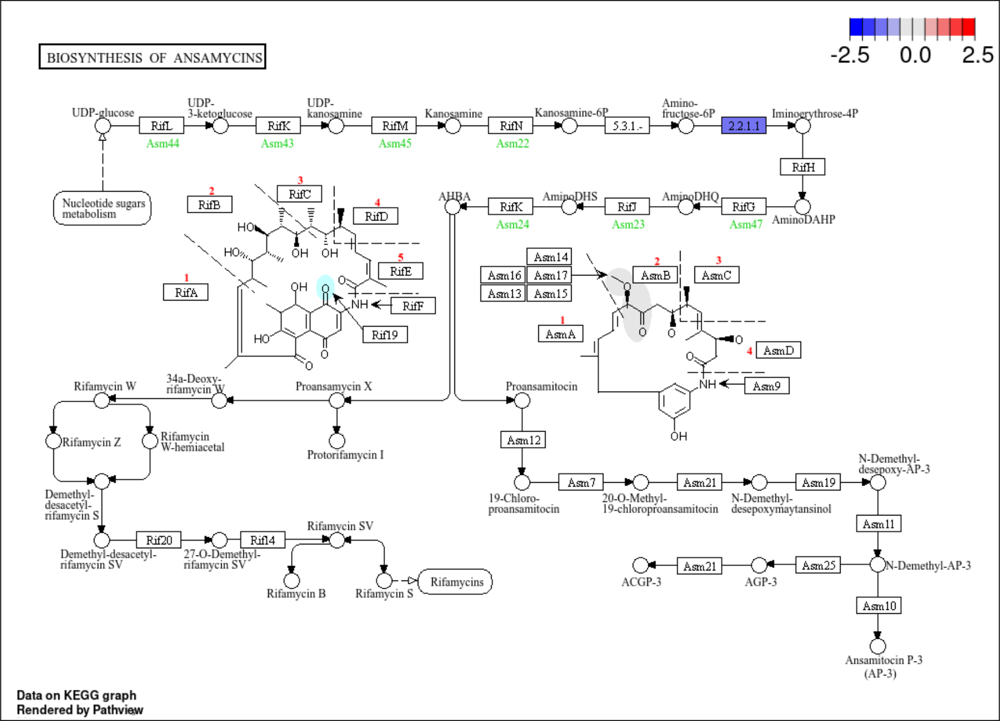

ko01051_Biosynthesis of ansamycins（アンサマイシン生合成）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 6 / 図に出る 6（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: BQOE01000001.1（2 水準）

表: 6 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 6.13 inch / 1ブロックの割り当て 24.75 inch）


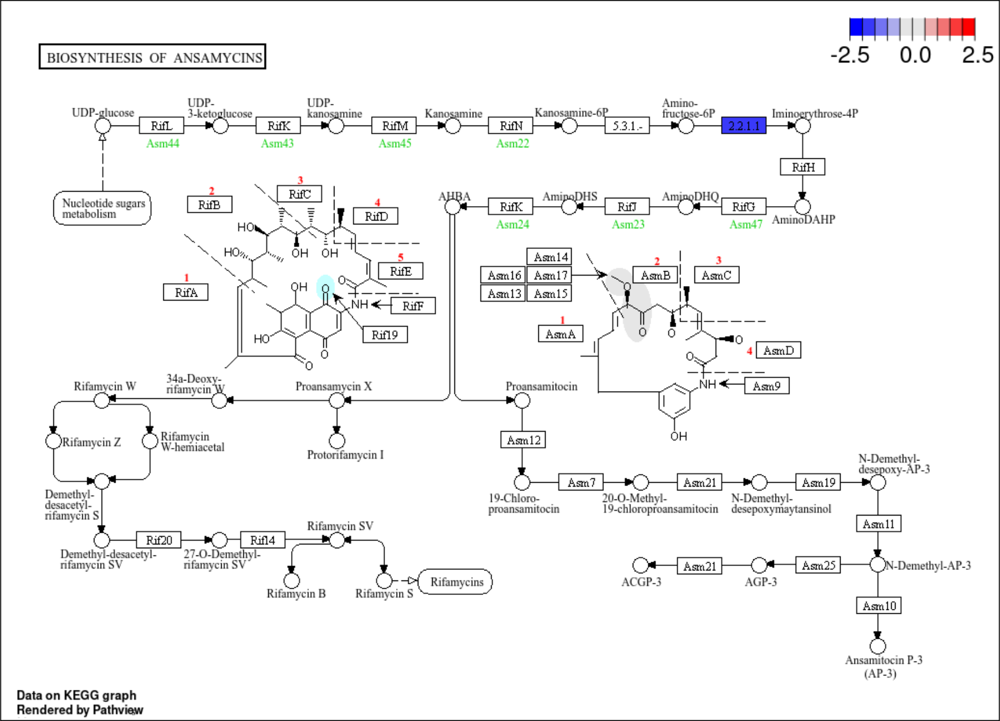

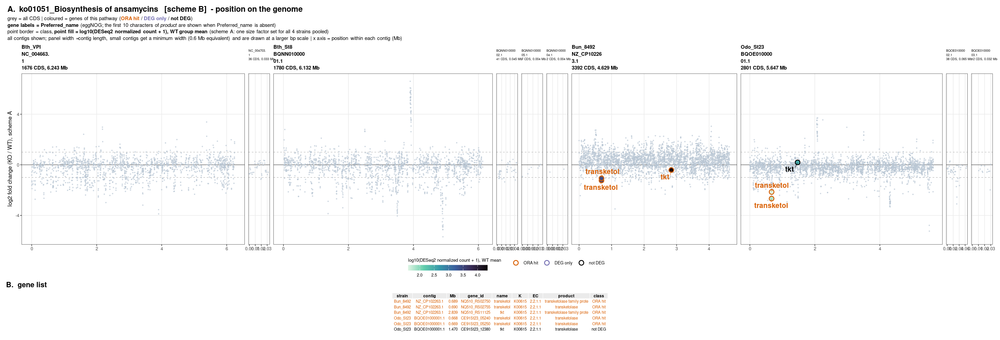

In [30]:
# ── 図A6-11: ko01051（アンサマイシン生合成）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko01051'; ko_jp = 'アンサマイシン生合成'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



(1) pathview - all genes of the pathway  [ko04146.B_all.png]
(2) pathview - ORA geneID only  [ko04146.B_ORA.png]


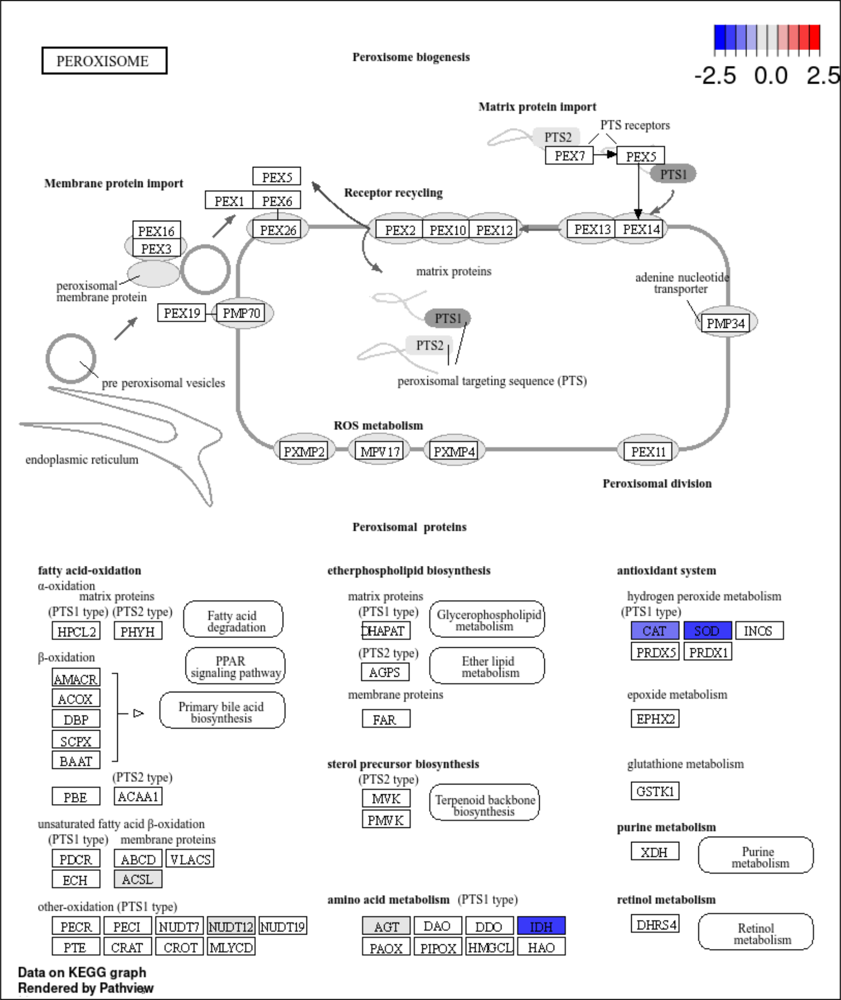

ko04146_Peroxisome（ペルオキシソーム）  contig 10 本（主 4 / 副 6）
   strain         contig  CDS 長さMb 描画幅
  Bth_VPI    NC_004663.1 1676  6.243   6.24
  Bth_VPI    NC_004703.1   36  0.033   0.60
  Bth_St8 BQNN01000001.1 1780  6.132   6.13
  Bth_St8 BQNN01000002.1   41  0.045   0.60
  Bth_St8 BQNN01000005.1    7  0.004   0.60
  Bth_St8 BQNN01000004.1    2  0.004   0.60
 Bun_8492  NZ_CP102263.1 3392  4.629   4.63
 Odo_St23 BQOE01000001.1 2801  5.647   5.65
 Odo_St23 BQOE01000002.1   38  0.065   0.60
 Odo_St23 BQOE01000003.1   12  0.032   0.60

経路の全遺伝子 24 / 図に出る 24（padj が NA で検定されなかったものも含めて表示）
凡例を出すパネル: NZ_CP102263.1（3 水準）

表: 24 行 → 1 ブロックに分けて横に並べる
表のフォント: 7.0 pt（最も広いブロック 8.59 inch / 1ブロックの割り当て 24.75 inch）


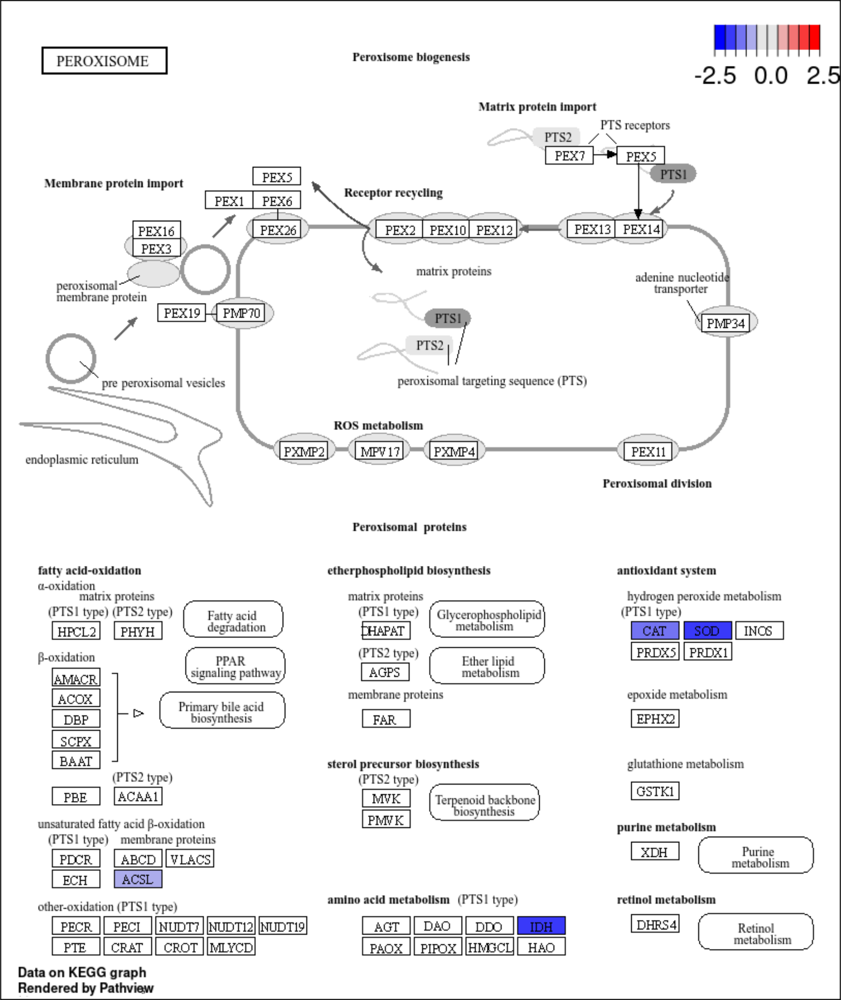

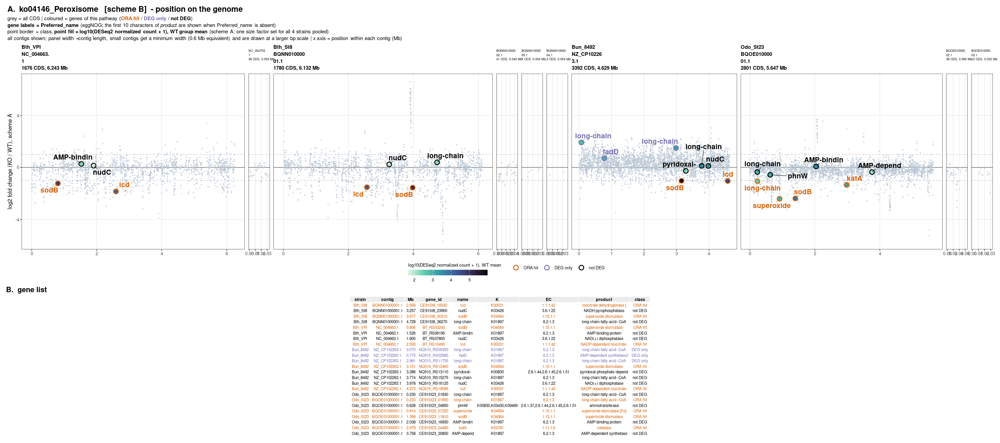

In [31]:
# ── 図A6-12: ko04146（ペルオキシソーム）  scheme B ───────────────────
# ★ ステージ6 セル13-1（図13-1）のコードをそのまま使っている。
#   違うのは下の ko / ko_jp / SCHEME の1行だけ。作図の手続きは完全に同じ
# セル4（準備）を先に実行しておくこと（col_cat / strains4 / MINW / dir_pv / dir_gp を使う）
#
# ★ 3つを続けて出す
#   (1) pathview（経路の全遺伝子）… 反応と化合物名。経路の中での位置づけ
#   (2) pathview（ORA の geneID のみ）… ORA が拾った反応だけ
#   (3) ゲノム位置マップ ＋ 遺伝子表 … どこにあるか、何の遺伝子か
library(ggplot2); library(ggtext); library(ggrepel); library(patchwork); library(ggpubr)
library(png); library(grid)

ko = 'ko04146'; ko_jp = 'ペルオキシソーム'; SCHEME = 'B'

# ── (1)(2) セル11 で作った pathview を再掲する ────────────────
# ★ 化合物名や反応の向きは pathview にしか無いので、地図の前に置く。
#   ORA で有意でない組み合わせ（例: ko03010 の scheme B）はファイルが無いので飛ばす
for (kind in c('all', 'ORA')) {
    f = file.path(dir_pv, sprintf('%s.%s_%s.png', ko, SCHEME, kind))
    tag = if (kind == 'all') '(1) pathview - all genes of the pathway' else
                             '(2) pathview - ORA geneID only'
    if (!file.exists(f)) {
        cat(sprintf("%s → ファイルなし（セル11 未実行、またはこのスキームの ORA で有意でない）\n", tag))
        next
    }
    # ★ セル11 の検品で落ちた図（ko00121）は中身が書かれず 0 バイトで残る。
    #   file.exists() は TRUE になるので、大きさも見ないと readPNG がエラーで止まる
    if (file.size(f) == 0) {
        cat(sprintf("%s → pathview が描けなかった（セル11 の検品で「★ 描画が壊れた」）\n", tag))
        next
    }
    im = readPNG(f); h_px = dim(im)[1]; w_px = dim(im)[2]
    W = 15; H = W * h_px / w_px
    if (H > 18) { H = 18; W = H * w_px / h_px }
    cat(sprintf("%s  [%s]\n", tag, basename(f)))
    options(repr.plot.width = W, repr.plot.height = H)
    grid.newpage(); grid.raster(im)
}

# ── (3) ゲノム位置マップ ＋ 遺伝子表 ──────────────────────────
tgt = ora$term[ora$source=='KEGG' & grepl(paste0('^',ko,'_'), ora$term)][1]
g_ora = ora %>% filter(scheme==SCHEME, source=='KEGG', term==tgt, padj<0.05) %>%
        pull(geneID) %>% strsplit('/') %>% unlist() %>% unique()
g_all = res %>% filter(!is.na(KEGG_Pathway), !marker) %>%
        dplyr::select(gene_id, KEGG_Pathway) %>% tidyr::separate_rows(KEGG_Pathway, sep=',') %>%
        filter(KEGG_Pathway==ko) %>% pull(gene_id) %>% unique()

# contig を CDS 数の多い順に並べる（主 → 副）
ctg = res %>% filter(biotype=='CDS', strain %in% strains4, !is.na(end)) %>%
    group_by(strain, contig) %>% summarise(CDS=dplyr::n(), 長さMb=max(end)/1e6, .groups='drop') %>%
    arrange(factor(strain, levels=strains4), desc(CDS)) %>%
    # ★ 描画幅は最小値で底上げするが、x 軸は contig の実際の長さに合わせる。
    #   → 副 contig は bp あたりの縮尺が主より大きくなり、パネルを目一杯使う
    mutate(幅 = pmax(長さMb, MINW),
           短名 = sub('^[^~]+~', '', contig),
           # ★ contig 名は空白が無いので str_wrap では折れない。
           #   パネルが狭いと重なるので、8文字ごとに改行を入れて縦に積む（文字は削らない）
           名表示 = gsub('(.{10})', '\\1\n', 短名))

cat(sprintf("%s（%s）  contig %d 本（主 4 / 副 %d）\n", tgt, ko_jp, nrow(ctg), nrow(ctg)-4))
print(ctg %>% transmute(strain, contig=短名, CDS, 長さMb=round(長さMb,3), 描画幅=round(幅,2)) %>%
      as.data.frame(), row.names=FALSE)

bg = res %>% filter(biotype=='CDS', !marker, !is.na(start)) %>%
     mutate(位置Mb = start/1e6)
fg = bg %>% filter(gene_id %in% g_all) %>%
     mutate(cat = case_when(gene_id %in% g_ora ~ 'ORA hit',
                            !is.na(padj_A) & padj_A < 0.05 ~ 'DEG only', TRUE ~ 'not DEG'),
            cat = factor(cat, levels=names(col_cat)),
            # ★ 丸の塗りに発現強度（WT 群の正規化カウント平均）を入れる。
            #   発現量は3〜4桁にわたるので log10 にする（0 があるので +1）
            発現 = log10(normA_WT + 1),
            label = ifelse(is.na(Preferred_name)|Preferred_name=='-', substr(product,1,10), Preferred_name))
cat(sprintf("\n経路の全遺伝子 %d / 図に出る %d（padj が NA で検定されなかったものも含めて表示）\n",
    length(g_all), nrow(fg)))

ylim = range(c(bg$LFC_A[bg$strain %in% strains4]), na.rm=TRUE)

# ★ 凡例は「3分類が最もそろって現れる contig」1枚からだけ出す。
#   drop=FALSE を付けても ★ データが無い水準はキーの点が描かれないため、
#   パネルごとに凡例の見た目が変わり、guides='collect' が別物と判定して2つ並ぶ
leg_i = which.max(sapply(ctg$contig, function(cc)
            length(unique(fg$cat[fg$contig == cc]))))
cat(sprintf("凡例を出すパネル: %s（%d 水準）\n",
            ctg$短名[leg_i], length(unique(fg$cat[fg$contig == ctg$contig[leg_i]]))))

subs = list()
for (i in 1:nrow(ctg)) {
    b = bg %>% filter(contig == ctg$contig[i])
    f = fg %>% filter(contig == ctg$contig[i])
    is_main = ctg$CDS[i] == max(ctg$CDS[ctg$strain == ctg$strain[i]])
    p = ggplot(b, aes(x=位置Mb, y=LFC_A)) +
        geom_hline(yintercept=0, colour='grey20', linewidth=0.3) +
        geom_hline(yintercept=c(-1,1), linetype='dashed', colour='grey65', linewidth=0.3) +
        geom_point(colour='#b9c6d4', size=0.5, alpha=0.6) +
        coord_cartesian(xlim=c(0, ctg$長さMb[i]), ylim=ylim) +
        labs(title = sprintf('%s\n%s\n%d CDS, %.3f Mb',
                             ifelse(is_main, as.character(ctg$strain[i]), ''),
                             ctg$名表示[i], ctg$CDS[i], ctg$長さMb[i]),
             x=NULL, y=if (i==1) 'log2 fold change (KO / WT), scheme A' else NULL) +
        theme_bw(base_size=10) +
        theme(plot.title=element_text(size=ifelse(is_main, 9, 5.5),
                                    face=ifelse(is_main,'bold','plain'), lineheight=1.15),
              panel.grid.minor=element_blank(),
              axis.text.y=if (i==1) element_text() else element_blank(),
              axis.ticks.y=if (i==1) element_line() else element_blank(),
              legend.position='bottom', legend.box='horizontal',
              legend.title=element_text(size=8), legend.text=element_text(size=7.5),
              legend.margin=margin(1,1,1,1),
              plot.margin=margin(2,2,0,2))
    # ★ 経路の遺伝子が無い contig（0 行）では colour の水準が1つも現れないため、
    #   scale_colour_manual が「No shared levels found」の警告を出す。
    #   図は正しく描かれる（空パネルに色が無いだけ）ので、描画時に警告だけ抑える
    # ★ shape 21（縁と塗りを別々に指定できる丸）を使う。
    #   縁 = 分類（ORA hit / DEG only / not DEG）、塗り = 発現強度
    p = p + geom_point(data=f, aes(colour=cat, fill=発現), shape=21,
                       size=3.2, stroke=1.1, show.legend = (i == leg_i))
    if (nrow(f) > 0)
        p = p +
                # ★ 遺伝子名は小さいと読めないので大きめに。
                #   重なりは ggrepel の force と box.padding で逃がす
                geom_text_repel(data=f, aes(label=label, colour=cat), size=4.4,
                                fontface='bold', max.overlaps=60, seed=1,
                                force=3, min.segment.length=0,
                                segment.size=0.3, box.padding=0.45, show.legend=FALSE)
    # ★ 色の scale は「各パネルに」付ける。
    #   patchwork の guides='collect' は収集時点のパネルごとの凡例を比べるので、
    #   後から & で当てると収集に間に合わず凡例が2つ残る。
    #   全パネルが colour の aes を持ち、drop=FALSE で水準が揃うので1つにまとまる
    subs[[i]] = p + scale_colour_manual(values=col_cat, name=NULL, drop=FALSE,
                                        guide = guide_legend(override.aes = list(
                                            fill='white', size=3.2, stroke=1.1))) +
        # ★ 凡例を下に横向きで出す。右に置くと凡例の文字幅ぶん地図が狭くなる
        scale_fill_viridis_c(option='mako', direction=-1,
                             limits=range(fg$発現, na.rm=TRUE),
                             name='log10(DESeq2 normalized count + 1), WT mean',
                             guide = guide_colourbar(direction='horizontal',
                                                     title.position='top',
                                                     barwidth=unit(5,'cm'),
                                                     barheight=unit(0.35,'cm')))
}
P = wrap_plots(subs, nrow=1, widths=ctg$幅) + plot_layout(guides='collect') +
    plot_annotation(title = sprintf('A.  %s   [scheme %s]  - position on the genome', tgt, SCHEME),
      subtitle = paste0("grey = all CDS  |  coloured = genes of this pathway  ",
                        "(<span style='color:#d95f02'>**ORA hit**</span> / ",
                        "<span style='color:#7570b3'>**DEG only**</span> / ",
                        "<span style='color:#000000'>**not DEG**</span>)<br>",
                        "**gene labels = Preferred_name** (eggNOG; the first 10 characters of *product* ",
                        "are shown when Preferred_name is absent)<br>",
                        "point border = class, **point fill = log10(DESeq2 normalized count + 1), ",
                        "WT group mean** (scheme A: one size factor set for all 4 strains pooled)<br>",
                        "all contigs shown; panel width ∝ contig length, ",
                        sprintf("small contigs get a minimum width (%.1f Mb equivalent) and are drawn at a larger bp scale  |  x axis = position within each contig (Mb)", MINW)),

      # ★ 収集した凡例の位置は patchwork 側の theme で決まる。
      #   サブプロットの theme に legend.position を書いても効かない
      theme = theme(plot.title=element_text(size=14, face='bold'),
                    plot.subtitle=element_markdown(size=9, lineheight=1.3),
                    legend.position='bottom', legend.box='horizontal',
                    legend.title=element_text(size=8.5),
                    legend.text=element_text(size=8)))
# ── 表を同じ図の中に入れる（panel B）──────────────────────────
# ★ 図だけでは locus_tag / K番号 / EC が分からないので表を下に並べる。
#   ggpubr::ggtexttable は表を ggplot として返すので patchwork に載せられる
library(ggpubr)

tbl = fg %>%
    mutate(K  = sapply(strsplit(gsub('ko:', '', ifelse(is.na(KEGG_ko), '-', KEGG_ko)), ','),
                       function(v) paste(v, collapse=',')),
           EC2 = ifelse(is.na(EC), '-', EC)) %>%
    transmute(strain, contig = sub('^[^~]+~', '', contig),
              Mb = round(位置Mb, 3), gene_id, name = label,
              K = K, EC = EC2, product = substr(product, 1, 26),
              # ★ LFC と padj は表に入れない。
              #   LFC は上の地図の y 軸そのもの、padj は分類（class）の色で示している。
              #   列を減らしたぶん1列あたりの幅が広がり、文字が重ならない
              class = as.character(cat)) %>%
    arrange(strain, Mb)

# ★ 縦に長くなりすぎるので、行を横に分割して並べる（1ブロック最大 24 行）
NROW_BLK = 24
nblk = ceiling(nrow(tbl) / NROW_BLK)
blks = split(1:nrow(tbl), ceiling(seq_along(1:nrow(tbl)) / ceiling(nrow(tbl)/nblk)))
cat(sprintf("\n表: %d 行 → %d ブロックに分けて横に並べる\n", nrow(tbl), length(blks)))

# ★ この図（地図＋表）だけ縦横 1.125 倍で出す（pathview の再掲は等倍のまま）
SCALE = 1.125
W_FIG = 22 * SCALE

# ★ 表のフォントは経路ごとに自動で決める。
#   列の幅は中身の文字数で決まるので、ko03010（112 遺伝子）のように行が多い経路では
#   ブロック数が増え、1ブロックに割ける幅が狭くなる。
#   固定の 6.2 pt のままだと表が割り当て幅をはみ出し、右端の class 列が切れてしまう。
#   → 実際に表を組んで幅を測り、収まる一番大きいフォントを選ぶ
#
# ★ 文字の幅は「フォントサイズに比例」しない。
#   小さいサイズでは hinting でカクカク変わる（実測: 5.5 pt で 4.75 inch、
#   5.9 pt で 5.04 inch）ので、計算で逆算せず 0.1 pt ずつ下げて実測で確かめる。
# ★ 測るときの device を間違えないこと。文字幅は device のフォント metrics で決まる。
#   実測（同じ表・同じ 5.9 pt）: pdf 4.70 / cairo png 4.81 / ragg 5.04 inch。
#   ggplot2 3.5 の ggsave は ragg があれば ragg を使うので、一番広く出る ragg で測る。
#   （Jupyter の画面表示は cairo png なので、ragg に合わせておけばどちらでも溢れない）
W_BLK = W_FIG / length(blks)             # 1ブロックに割ける幅 (inch)
ragg::agg_png(tempfile(fileext = '.png'), width = 1000, height = 1000, res = 100)
for (fs_try in seq(7.0, 3.4, by = -0.1)) {
    w_max = 0
    for (b in seq_along(blks)) {
        tg0 = gridExtra::tableGrob(
                  tbl[blks[[b]], ], rows = NULL,
                  theme = ttheme(base_size = fs_try, padding = unit(c(2.2, 1.6), 'mm'),
                                 colnames.style = colnames_style(size = fs_try + 0.4),
                                 tbody.style = tbody_style(size = fs_try)))
        w_max = max(w_max, sum(convertWidth(tg0$widths, 'in', valueOnly = TRUE)))
    }
    FS = fs_try
    if (w_max <= W_BLK * 0.98) break     # 0.98 は plot.margin のぶんの余裕
}
invisible(dev.off())
cat(sprintf("表のフォント: %.1f pt（最も広いブロック %.2f inch / 1ブロックの割り当て %.2f inch）\n",
            FS, w_max, W_BLK))

# ★ 表の文字色を地図と揃える（ORA hit = 橙 / DEG only = 紫 / not DEG = 黒）。
#   ggtexttable（gridExtra の tableGrob）は色を ★ 列方向（column-major）に展開する ので、
#   行ごとの色ベクトルを列数ぶん「繰り返して」渡す（rep(col, ncol) であって each= ではない。
#   each= にすると列ごとに1色になる。実測で確認）
tg = lapply(seq_along(blks), function(b) {
    ix  = blks[[b]]
    col = unname(col_cat[tbl$class[ix]])
    g = ggtexttable(tbl[ix, ], rows = NULL,
                theme = ttheme(base_size = FS, padding = unit(c(2.2, 1.6), 'mm'),
                               colnames.style = colnames_style(size = FS + 0.4, fill = 'grey92'),
                               tbody.style = tbody_style(size = FS, fill = 'white',
                                                         color = rep(col, ncol(tbl)))))
    g = g + theme(plot.margin = margin(0, 2, 2, 2))
    if (b == 1) g = g + labs(title = 'B.  gene list') +
        theme(plot.title = element_text(size = 13, face = 'bold', hjust = 0,
                                        margin = margin(b = 2)))
    g
})
TB = wrap_plots(tg, nrow = 1)

# ★ 表（ggtexttable）はパネルの中央に置かれるので、割り当てた高さが余ると
#   上下に空白ができる。行数から必要な高さを詰めて見積もる
H_map = 6.4
H_tab = 0.125 * max(sapply(blks, length)) + 0.35
# ★ tag_levels は使わない。patchwork の全サブプロット（contig パネル10個 + 表3枚）に
#   A〜M と振られてしまうため。見出しは A の図タイトルと B の表タイトルで示す。
#
# ★ wrap_elements() で包む。
#   patchwork を入れ子（P / TB）にすると ★ 内側の plot_annotation が描画されず、
#   A のタイトルが消える。包むと内側が1つの要素として確定し、タイトルが残る
PB = (wrap_elements(full = P) / TB) + plot_layout(heights = c(H_map, H_tab))

# SCALE / W_FIG は表のフォントを決めるときに上で定義してある
suppressWarnings(suppressMessages(
    ggsave(file.path(dir_gp, sprintf('genomepos_%s_%s.png', ko, SCHEME)), PB,
           width = W_FIG, height = (H_map + H_tab) * SCALE,
           dpi = 100, limitsize = FALSE)))
options(repr.plot.width = W_FIG, repr.plot.height = (H_map + H_tab) * SCALE)
suppressWarnings(print(PB))



### 考察: 散在が基本。隣接していても協調して動くとは限らない

どの経路も遺伝子はゲノム上に散在し、数百 kb 〜 数 Mb 離れている。
ステージ6 セル13 の「経路の遺伝子は1オペロンではない」と同じ。

ただし 0 kb 隣接のペア・塊はいくつかある。

- `sucD`–`sucC`（Bth_VPI、`ko00640` / `ko00660` の両方に出る）
- `gnd`–`zwf`（Bun_8492、`ko00480`）… ステージ7 で PPP 酸化分枝の枠として検出した座位と同じ
- `leuC`–`leuD`–`leuA_1`–`leuB`（Bun_8492、`ko00660`）… 4遺伝子が連続
- transketolase 2本（Bun_8492、`ko01051`）

★ このうち `leu` の4連は**隣接しているのに Bun_8492 では1つも有意でない**。
隣接＝協調して動く、ではないことがこの図で確認できる。

# 付録のまとめ

ステージ6 で図にしていた 7 経路に 6 経路を足して 13 経路にした。
作図の手続きはセル12 / セル13 と完全に同じで、検定は1つもやり直していない。

★ **新しく見えたのは `ko00640` プロピオン酸代謝だけだった。**
残り5経路（グルタチオン代謝・C5分岐二塩基酸代謝・アンサマイシン生合成・ペルオキシソーム・
セレン化合物代謝）で下がっていた遺伝子は、`gnd` `zwf` `icd` `sucC` `sucD` `sodB` `katA`
`sufS` `trxB` `tkt` といった、ステージ6・ステージ7 で既に議論した遺伝子である。
KEGG が同じ遺伝子を複数の経路名に載せているためで、**有意になった経路名を数えることと、
動いている遺伝子を数えることは別**だと分かる。

★ `ko00640` だけは独自の遺伝子（`prpC` `mutA` `mutB` `accC` `ackA` `pta`）を持ち、
Bth 2株で下がり Bun_8492 では逆に上がる。株ごとに向きが分かれる経路として
ステージ7 の単独遺伝子図と同じ扱いで追う価値がある。

★ ORA で有意だった KEGG 経路は 22 本あり、図にしたのはこれで 13 本。
残り9本（`ko00195` Photosynthesis、`ko00190` Oxidative phosphorylation、`ko00620` Pyruvate
metabolism、`ko00310` Lysine degradation、`ko04016` / `ko04013` MAPK、`ko04068` FoxO、
`ko00970` Aminoacyl-tRNA、`ko03008` Ribosome biogenesis）はこの付録に同じ形で足せる。